# CS781 Capstone · Phase 3 · Rhetorical Role Prediction (RR)

In [1]:
import os, sys, subprocess, json, glob, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "regex", "huggingface_hub"], check=False)
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
os.makedirs(f"{WORK}/p3rr/phase1_models", exist_ok=True); os.makedirs(f"{WORK}/tests", exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
import torch
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)] or "NONE (enable GPU!)")

torch 2.11.0+cu128 | GPUs: ['Tesla T4', 'Tesla T4']


## Pipeline code (written to `p3rr/`; nothing to edit)

In [2]:
%%writefile {WORK}/p3rr/phase1_models/common.py
"""Shared building blocks (RMSNorm, RoPE, SwiGLU, init).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (identical in A/B/C/D notebooks, cell 19),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x, pos0=0):
        T = x.size(-2)
        assert pos0 + T <= self.cos.size(0), f"position {pos0 + T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[pos0:pos0 + T], self.sin[pos0:pos0 + T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))

def init_weights_(model, n_layer):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
    for name, p in model.named_parameters():
        if name.endswith("proj.weight"):
            nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

def lm_loss(logits, targets):
    return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

Writing /kaggle/working/p3rr/phase1_models/common.py


In [3]:
%%writefile {WORK}/p3rr/phase1_models/arch_a.py
"""Architecture A: decoder-only LLaMA-style (GQA, RoPE, SwiGLU).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (decoder-only-fine-tuned.ipynb / decoder-only-transformer-llama-style.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class GQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd = n_head, n_kv_head, d_model // n_head
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        if self.n_kv != self.n_head:
            rep = self.n_head // self.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_head, n_kv_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class LlamaLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=12, n_head=10, n_kv_head=2, d_model=640,
                 ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[LlamaLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = LlamaLM

Writing /kaggle/working/p3rr/phase1_models/arch_a.py


In [4]:
%%writefile {WORK}/p3rr/phase1_models/arch_b.py
"""Architecture B: encoder-decoder.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (B/notebookc976077ad3.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class SelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, key_mask=None, causal=False, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        mask = None if key_mask is None else key_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal and T > 1 and mask is None,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class CrossAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        self.n_head, self.hd = n_head, d_model // n_head
        self.q = nn.Linear(d_model, d_model, bias=bias)
        self.kv = nn.Linear(d_model, 2 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, memory, mem_mask, cache=None):
        B, T, C = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        if cache is not None and "ck" in cache:
            k, v = cache["ck"], cache["cv"]
        else:
            S = memory.size(1)
            k, v = self.kv(memory).view(B, S, 2, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
            if cache is not None:
                cache["ck"], cache["cv"] = k, v
        mask = None if mem_mask is None else mem_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = SelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, key_mask):
        x = x + self.attn(self.norm1(x), rope, 0, key_mask=key_mask, causal=False)
        return x + self.ffn(self.norm2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = RMSNorm(d_model), RMSNorm(d_model), RMSNorm(d_model)
        self.self_attn = SelfAttention(d_model, n_head, dropout, bias)
        self.cross_attn = CrossAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, memory, mem_mask, pos0=0, cache=None):
        x = x + self.self_attn(self.norm1(x), rope, pos0, causal=True, cache=cache)
        x = x + self.cross_attn(self.norm2(x), memory, mem_mask, cache=cache)
        return x + self.ffn(self.norm3(x))

class EncDecLM(nn.Module):
    def __init__(self, vocab_size, enc_block, dec_block, pad_id=None, n_enc_layer=6, n_dec_layer=6,
                 n_head=9, d_model=576, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EncDecLM] ignoring unknown config keys: {sorted(kw)}")
        self.enc_block, self.dec_block, self.pad_id = enc_block, dec_block, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        hd = d_model // n_head
        self.enc_rope = RotaryEmbedding(hd, enc_block, rope_theta)
        self.dec_rope = RotaryEmbedding(hd, dec_block, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_enc_layer)])
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_dec_layer)])
        self.enc_norm, self.dec_norm = RMSNorm(d_model), RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_enc_layer + n_dec_layer)
        self.lm_head.weight = self.tok_emb.weight

    def encode(self, src, src_mask=None):
        assert src.size(1) <= self.enc_block, f"source length {src.size(1)} > enc_block {self.enc_block}"
        if src_mask is not None and bool(src_mask.all()):
            src_mask = None
        x = self.drop(self.tok_emb(src))
        for blk in self.enc_blocks:
            x = blk(x, self.enc_rope, src_mask)
        return self.enc_norm(x)

    def decode(self, dec_in, memory, mem_mask=None, pos0=0, caches=None, last_only=False):
        assert pos0 + dec_in.size(1) <= self.dec_block, f"decoder position {pos0 + dec_in.size(1)} > dec_block"
        if mem_mask is not None and bool(mem_mask.all()):
            mem_mask = None
        x = self.drop(self.tok_emb(dec_in))
        for i, blk in enumerate(self.dec_blocks):
            x = blk(x, self.dec_rope, memory, mem_mask, pos0, None if caches is None else caches[i])
        x = self.dec_norm(x)
        if last_only:
            x = x[:, -1:]
        return self.lm_head(x)

    def forward(self, src, src_mask, dec_in, targets=None):
        memory = self.encode(src, src_mask)
        logits = self.decode(dec_in, memory, src_mask)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EncDecLM

Writing /kaggle/working/p3rr/phase1_models/arch_b.py


In [5]:
%%writefile {WORK}/p3rr/phase1_models/arch_c.py
"""Architecture C: encoder/hybrid prefix-LM + MLM (UniLM-style).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (C/encoder-hybrid.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class HybridSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, attn_mask=None, causal=True, pos0=0, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                           is_causal=causal and attn_mask is None and T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = HybridSelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, attn_mask, causal, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, attn_mask, causal, pos0, cache)
        return x + self.ffn(self.norm2(x))

class HybridLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=10, n_head=10, d_model=640, ffn_mult=8 / 3,
                 dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, n_segments=3, **kw):
        super().__init__()
        if kw:
            print(f"[HybridLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.seg_emb = nn.Embedding(n_segments, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        nn.init.zeros_(self.seg_emb.weight)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def hybrid_mask(prefix_len, T):
        pos = torch.arange(T, device=prefix_len.device)
        in_prefix = pos[None, None, :] < prefix_len[:, None, None]
        causal = pos[None, :, None] >= pos[None, None, :]
        return (in_prefix | causal)[:, None]

    def forward(self, idx, prefix_len=None, seg=None, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        if prefix_len is None:
            prefix_len = torch.zeros(B, dtype=torch.long, device=idx.device)
        prefix_len = prefix_len.to(idx.device).long().clamp(0, T)
        if bool((prefix_len == 0).all()):
            attn_mask, causal = None, True
        elif bool((prefix_len == T).all()):
            attn_mask, causal = None, False
        else:
            attn_mask, causal = self.hybrid_mask(prefix_len, T), False
        if seg is None:
            seg = (torch.arange(T, device=idx.device)[None, :] >= prefix_len[:, None]).long()
        x = self.drop(self.tok_emb(idx) + self.seg_emb(seg))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, attn_mask, causal, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = HybridLM

Writing /kaggle/working/p3rr/phase1_models/arch_c.py


In [6]:
%%writefile {WORK}/p3rr/phase1_models/arch_d.py
"""Architecture D: efficient decoder, sliding-window attention + MQA.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (D/notebook7e00370b82.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class LocalMQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd, self.window = n_head, n_kv_head, d_model // n_head, window
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)
        self._mask_cache = {}

    def _block_mask(self, nb, device):
        key = (nb, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            W = self.window
            a = torch.arange(W, device=device)[:, None]
            b = torch.arange(2 * W, device=device)[None, :]
            keep = ((b > a) & (b <= a + W))[None].repeat(nb, 1, 1)
            keep[0, :, :W] = False
            m = keep[None, None].expand(1, self.n_head, nb, W, 2 * W).reshape(1, self.n_head * nb, W, 2 * W)
            self._mask_cache = {key: m}
        return m

    def _blocked(self, q, k, v):
        B, H, T, hd = q.shape
        W, Hkv = self.window, k.size(1)
        Tp = -(-T // W) * W
        if Tp != T:
            q, k, v = (F.pad(t, (0, 0, 0, Tp - T)) for t in (q, k, v))
        nb = Tp // W
        k = F.pad(k, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        v = F.pad(v, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        rep = H // Hkv
        k = k[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        v = v[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        qb = q.reshape(B, H * nb, W, hd)
        y = F.scaled_dot_product_attention(qb, k, v, attn_mask=self._block_mask(nb, q.device),
                                           dropout_p=self.dropout if self.training else 0.0)
        return y.reshape(B, H, Tp, hd)[:, :, :T]

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None and "k" in cache:
            assert T == 1, "cached decoding feeds one token at a time"
            k = torch.cat([cache["k"], k], 2)[:, :, -self.window:]
            v = torch.cat([cache["v"], v], 2)[:, :, -self.window:]
            cache["k"], cache["v"] = k, v
            rep = self.n_head // self.n_kv
            y = F.scaled_dot_product_attention(q, k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1))
        else:
            y = self._blocked(q, k, v)
            if cache is not None:
                cache["k"], cache["v"] = k[:, :, -self.window:], v[:, :, -self.window:]
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = LocalMQAttention(d_model, n_head, n_kv_head, window, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class EfficientLM(nn.Module):
    def __init__(self, vocab_size, block_size, window=256, pad_id=None, n_layer=12, n_head=10, n_kv_head=1,
                 d_model=640, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, rope_max_len=8192,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EfficientLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.window, self.pad_id, self.n_layer = block_size, window, pad_id, n_layer
        self.max_pos = max(rope_max_len, block_size)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, self.max_pos, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, window, hidden, dropout, bias)
                                     for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EfficientLM

Writing /kaggle/working/p3rr/phase1_models/arch_d.py


In [7]:
%%writefile {WORK}/p3rr/phase1_models/__init__.py
from .arch_a import LlamaLM
from .arch_b import EncDecLM
from .arch_c import HybridLM
from .arch_d import EfficientLM

MODEL_CLASSES = {c.__name__: c for c in (LlamaLM, EncDecLM, HybridLM, EfficientLM)}

Writing /kaggle/working/p3rr/phase1_models/__init__.py


In [8]:
%%writefile {WORK}/p3rr/__init__.py
"""CS781 Capstone Phase 3: Rhetorical Role prediction on top of the Phase-1 legal language models."""

Writing /kaggle/working/p3rr/__init__.py


In [9]:
%%writefile {WORK}/p3rr/tokenizer.py
"""Byte-level BPE tokenizer from Phase 1 (load-only copy) + character offsets for NER.

Phase 1 trained the merges; here we only *load* them (same ids as pretraining) and add
`encode_with_offsets`, which returns for every token the character span it covers in the original text.

Offsets are computed per pre-token: the regex gives each pre-token's char span, BPE splits the pre-token's
UTF-8 bytes into tokens, and a byte->char table maps every token's byte range back to characters.
"""
import hashlib
import json
import os
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import regex as re_u

SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

FINE_PUNCT_PATTERN = (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}{1,3}| ?[^\s\p{L}\p{N}]|\s*[\r\n]+|\s+(?!\S)|\s+""")

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

@dataclass
class Encoded:
    ids: list
    starts: list
    ends: list

class BPETokenizer:
    def __init__(self, merges, pattern, specials=SPECIAL_TOKENS, fine_punct=False):
        self.base_pattern = pattern
        self.fine_punct = fine_punct
        self.pattern = FINE_PUNCT_PATTERN if fine_punct else pattern
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in merges]
        self.specials = list(specials)
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.n_regular = base
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self.cache = {}
        self._oc, self._oc_path, self._oc_new = None, None, 0

    def fingerprint(self):
        h = hashlib.sha1(self.pattern.encode())
        h.update(json.dumps(self.merges).encode())
        return h.hexdigest()[:12]

    def enable_disk_cache(self, cache_dir):
        Path(cache_dir).mkdir(parents=True, exist_ok=True)
        self._oc_path = Path(cache_dir) / f"offsets_{self.fingerprint()}.pkl"
        self._oc = {}
        if self._oc_path.exists():
            try:
                self._oc = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                self._oc = {}
        return self

    def save_disk_cache(self):
        if self._oc is None or not self._oc_new:
            return
        disk = {}
        if self._oc_path.exists():
            try:
                disk = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                disk = {}
        disk.update(self._oc)
        tmp = self._oc_path.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(disk, open(tmp, "wb"), protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self._oc_path)
        self._oc, self._oc_new = disk, 0

    @classmethod
    def load(cls, path, fine_punct=False):
        d = json.load(open(path, encoding="utf-8"))
        return cls(d["merges"], d["pattern"], d.get("specials", SPECIAL_TOKENS), fine_punct=fine_punct)

    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode_with_offsets(self, text):
        if self._oc is not None:
            key = hashlib.sha1(text.encode("utf-8")).hexdigest()
            hit = self._oc.get(key)
            if hit is not None:
                return Encoded(hit[0].tolist(), hit[1].tolist(), hit[2].tolist())
            enc = self._encode_with_offsets(text)
            self._oc[key] = (np.asarray(enc.ids, dtype=np.int32), np.asarray(enc.starts, dtype=np.int32),
                             np.asarray(enc.ends, dtype=np.int32))
            self._oc_new += 1
            return enc
        return self._encode_with_offsets(text)

    def _encode_with_offsets(self, text):
        ids, starts, ends = [], [], []
        for m in self.pat.finditer(text):
            w, c0 = m.group(), m.start()
            wid = self._encode_word(w)
            if len(wid) == 1:
                ids.append(wid[0]); starts.append(c0); ends.append(m.end())
                continue
            b2c = []
            for ci, ch in enumerate(w):
                b2c.extend([ci] * len(ch.encode("utf-8")))
            b = 0
            for t in wid:
                nb = len(self.vocab[t])
                ids.append(t)
                starts.append(c0 + b2c[b])
                ends.append(c0 + b2c[b + nb - 1] + 1)
                b += nb
        return Encoded(ids, starts, ends)

    def decode(self, ids):
        return b"".join(self.vocab[int(i)] for i in ids if int(i) < self.n_regular).decode("utf-8", errors="replace")

Writing /kaggle/working/p3rr/tokenizer.py


In [10]:
%%writefile {WORK}/p3rr/data.py
"""Phase-3 data: download, load, validate, statistics.

Layout (HF dataset Exploration-Lab/CS-781-Capstone, folder Phase_3_RR):
    Train/CL_train.json, Train/CL_dev.json, Train/IT_train.json, Train/IT_dev.json, Train/label_vocab.json
    Test/CL_test.json, Test/IT_test.json
A document is {"id": ..., "text": [sentence, ...], "labels": [label, ...]} (no "labels" in the test files).
The loader also accepts a dict {id: {...}} or JSON-lines, and the keys "sentences"/"doc_id"/"label",
so a small format difference in the released files does not break the pipeline.

Loaded form: {"labels": [...], "train"/"dev"/"test": {doc_id: {"id", "domain", "sents", "labels" | None}}}
"""
import json
import os
from collections import Counter
from pathlib import Path

import numpy as np

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_SUBDIR = "Phase_3_RR"
DOMAINS = ("CL", "IT")
SPLITS = ("train", "dev", "test")

def download(local_dir, token=None):
    from huggingface_hub import snapshot_download
    token = token or os.environ.get("HF_TOKEN")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=local_dir, token=token,
                      allow_patterns=[f"{HF_SUBDIR}/*"])
    return Path(local_dir) / HF_SUBDIR

def find_data_dir(candidates=()):
    roots = [Path(c) for c in candidates if c] + [Path("/kaggle/input")]
    for r in roots:
        if not r.exists():
            continue
        if (r / "Train" / "label_vocab.json").exists():
            return r
        for p in r.rglob("label_vocab.json"):
            if p.parent.name == "Train":
                return p.parent.parent
    return None

def split_path(data_dir, split, dom):
    d = Path(data_dir)
    return d / ("Test" if split == "test" else "Train") / f"{dom}_{split}.json"

def _read_json(path):
    txt = Path(path).read_text(encoding="utf-8")
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return [json.loads(line) for line in txt.splitlines() if line.strip()]

def _records(raw):
    if isinstance(raw, dict):
        for k in ("data", "documents", "docs"):
            if isinstance(raw.get(k), list):
                return raw[k]
        recs = []
        for k, v in raw.items():
            if isinstance(v, dict):
                recs.append({"id": k, **v})
            elif isinstance(v, list):
                recs.append({"id": k, "text": v})
            else:
                raise ValueError(f"unexpected value type for document {k}: {type(v)}")
        return recs
    if isinstance(raw, list):
        return raw
    raise ValueError(f"unexpected top-level JSON type {type(raw)}")

def _first(r, keys):
    for k in keys:
        if k in r and r[k] is not None:
            return r[k]
    return None

def _norm_doc(r, dom, where):
    did = _first(r, ("id", "doc_id", "document_id", "docid"))
    sents = _first(r, ("text", "sentences", "sents"))
    labels = _first(r, ("labels", "label", "roles", "rhetorical_roles"))
    if did is None:
        raise ValueError(f"{where}: document without an id field: keys {sorted(r)}")
    if not isinstance(sents, list):
        raise ValueError(f"{where}: document {did}: 'text' must be a list of sentences, got {type(sents)}")
    if labels is not None and len(labels) == 0 and len(sents) > 0:
        labels = None
    if labels is not None and len(labels) != len(sents):
        raise ValueError(f"{where}: document {did}: {len(sents)} sentences but {len(labels)} labels")
    return {"id": str(did), "domain": dom, "sents": ["" if s is None else str(s) for s in sents],
            "labels": None if labels is None else [str(l) for l in labels]}

def load_vocab(path):
    raw = _read_json(path)
    if isinstance(raw, dict):
        for k in ("labels", "label_vocab", "vocab"):
            if k in raw:
                return load_vocab_obj(raw[k])
    return load_vocab_obj(raw)

def load_vocab_obj(raw):
    if isinstance(raw, list):
        return [str(x) for x in raw]
    if isinstance(raw, dict):
        vals = list(raw.values())
        if all(isinstance(v, int) for v in vals):
            return [k for k, _ in sorted(raw.items(), key=lambda kv: kv[1])]
        if all(isinstance(v, str) for v in vals):
            return [v for _, v in sorted(raw.items(), key=lambda kv: int(kv[0]))]
    raise ValueError(f"cannot parse label_vocab.json: {raw!r:.200}")

def load_phase3(data_dir, max_docs=None):
    data_dir = Path(data_dir)
    labels = load_vocab(data_dir / "Train" / "label_vocab.json")
    assert len(set(labels)) == len(labels), f"duplicate labels in label_vocab.json: {labels}"
    out = {"labels": labels, "data_dir": str(data_dir)}
    for split in SPLITS:
        out[split] = {}
        for dom in DOMAINS:
            p = split_path(data_dir, split, dom)
            if not p.exists():
                raise FileNotFoundError(p)
            recs = _records(_read_json(p))
            if max_docs:
                recs = recs[:max_docs]
            for r in recs:
                d = _norm_doc(r, dom, p.name)
                if d["id"] in out[split]:
                    raise ValueError(f"document id {d['id']} appears twice in the {split} split "
                                     f"({out[split][d['id']]['domain']} and {dom}): one prediction.json cannot hold both")
                out[split][d["id"]] = d
    lab = set(labels)
    for split in ("train", "dev"):
        bad = Counter(l for d in out[split].values() for l in (d["labels"] or []) if l not in lab)
        assert not bad, f"{split} labels not in label_vocab.json: {dict(bad)}"
        missing = [k for k, d in out[split].items() if d["labels"] is None]
        assert not missing, f"{split} documents without labels: {missing[:5]}"
    return out

def describe_raw(data_dir, n_chars=300):
    data_dir = Path(data_dir)
    print("label_vocab.json:", json.dumps(_read_json(data_dir / "Train" / "label_vocab.json"))[:400])
    for split in SPLITS:
        for dom in DOMAINS:
            p = split_path(data_dir, split, dom)
            raw = _read_json(p)
            recs = _records(raw)
            first = recs[0] if recs else {}
            print(f"{p.name}: top-level {type(raw).__name__}, {len(recs)} docs, keys {sorted(first)} | "
                  f"{json.dumps(first)[:n_chars]}")

def stats(data, tok=None):
    labels = data["labels"]
    out = {}
    for split in SPLITS:
        for dom in DOMAINS:
            docs = [d for d in data[split].values() if d["domain"] == dom]
            n_s = [len(d["sents"]) for d in docs]
            rec = {"docs": len(docs), "sentences": int(sum(n_s)),
                   "sents_per_doc": {"mean": round(float(np.mean(n_s)), 1) if n_s else 0, "min": min(n_s or [0]),
                                     "max": max(n_s or [0])}}
            words = [len(s.split()) for d in docs for s in d["sents"]]
            if words:
                rec["words_per_sent"] = {q: int(np.percentile(words, p)) for q, p in (("p50", 50), ("p90", 90), ("p99", 99), ("max", 100))}
                rec["empty_sentences"] = sum(1 for d in docs for s in d["sents"] if not s.strip())
            if tok is not None and words:
                lens = [len(tok.encode(" " + s.strip())) for d in docs[:40] for s in d["sents"]]
                rec["tokens_per_sent(first 40 docs)"] = {q: int(np.percentile(lens, p)) for q, p in (("p50", 50), ("p90", 90), ("p99", 99), ("max", 100))}
            if split != "test":
                c = Counter(l for d in docs for l in d["labels"])
                rec["label_counts"] = {l: c.get(l, 0) for l in labels}
            out[f"{split}/{dom}"] = rec
    pos = {l: [] for l in labels}
    trans = Counter()
    for d in data["train"].values():
        n = len(d["labels"])
        for i, l in enumerate(d["labels"]):
            pos[l].append(i / max(1, n - 1))
            if i:
                trans[(d["labels"][i - 1], l)] += 1
    out["mean_relative_position(train)"] = {l: round(float(np.mean(v)), 2) for l, v in pos.items() if v}
    same = sum(v for (a, b), v in trans.items() if a == b)
    out["label_repeats_previous(train)"] = round(same / max(1, sum(trans.values())), 3)
    out["top_transitions(train, a!=b)"] = [f"{a}->{b}: {v}" for (a, b), v in trans.most_common(40) if a != b][:12]
    return out

Writing /kaggle/working/p3rr/data.py


In [11]:
%%writefile {WORK}/p3rr/metrics.py
"""Sentence-level metrics for rhetorical roles + error analysis.

macro_f1 follows sklearn's f1_score(average="macro") on the flattened sentence labels: per-label F1 averaged
over the labels that occur in the gold OR the predictions (a label absent from both is left out).
macro_f1_vocab averages over all labels of label_vocab.json (absent labels count as 0) - a stricter variant.
Cross-check against the official evaluation script from the course Drive before trusting small differences.
"""
from collections import Counter

import numpy as np

def _prf(tp, fp, fn):
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return p, r, f

def flatten(gold, pred, ids=None):
    g, p = [], []
    for d in (ids if ids is not None else gold):
        assert len(gold[d]) == len(pred[d]), f"{d}: {len(gold[d])} gold vs {len(pred[d])} predicted sentences"
        g += list(gold[d]); p += list(pred[d])
    return g, p

def scores(gold, pred, labels, ids=None):
    g, p = flatten(gold, pred, ids)
    tp, fp, fn = Counter(), Counter(), Counter()
    for a, b in zip(g, p):
        if a == b:
            tp[a] += 1
        else:
            fp[b] += 1; fn[a] += 1
    support = Counter(g)
    per = {}
    for l in labels:
        pr, rc, f = _prf(tp[l], fp[l], fn[l])
        per[l] = {"p": pr, "r": rc, "f1": f, "support": support[l], "predicted": tp[l] + fp[l]}
    present = [l for l in labels if support[l] or tp[l] + fp[l]]
    mean = lambda key, ls: float(np.mean([per[l][key] for l in ls])) if ls else 0.0
    return {"macro_f1": mean("f1", present), "macro_p": mean("p", present), "macro_r": mean("r", present),
            "macro_f1_vocab": mean("f1", labels), "accuracy": sum(tp.values()) / max(1, len(g)),
            "n_sentences": len(g), "labels_in_average": len(present), "per_label": per}

def confusion(gold, pred, labels, ids=None):
    g, p = flatten(gold, pred, ids)
    idx = {l: i for i, l in enumerate(labels)}
    m = np.zeros((len(labels), len(labels)), dtype=np.int64)
    for a, b in zip(g, p):
        m[idx[a], idx[b]] += 1
    return m

def top_confusions(cm, labels, k=12):
    pairs = [(int(cm[i, j]), labels[i], labels[j]) for i in range(len(labels)) for j in range(len(labels)) if i != j and cm[i, j]]
    return [f"{a} -> {b}: {n}" for n, a, b in sorted(pairs, reverse=True)[:k]]

def full_report(gold, pred, labels, domain_of):
    ids = list(gold)
    rep = {"all": scores(gold, pred, labels, ids)}
    for dom in sorted(set(domain_of.values())):
        di = [d for d in ids if domain_of[d] == dom]
        if di:
            rep[dom] = scores(gold, pred, labels, di)
    cm = confusion(gold, pred, labels, ids)
    rep["confusion"] = cm.tolist()
    rep["top_confusions"] = top_confusions(cm, labels)
    at_change = inside = 0
    for d in ids:
        gs, ps = gold[d], pred[d]
        for i, (a, b) in enumerate(zip(gs, ps)):
            if a != b:
                if (i > 0 and gs[i - 1] != a) or (i + 1 < len(gs) and gs[i + 1] != a):
                    at_change += 1
                else:
                    inside += 1
    rep["errors_at_label_change"], rep["errors_inside_run"] = at_change, inside
    try:
        from sklearn.metrics import f1_score
        g, p = flatten(gold, pred, ids)
        rep["sklearn_macro_f1"] = float(f1_score(g, p, average="macro", zero_division=0))
    except Exception:
        pass
    return rep

def format_table(sc):
    lines = [f"{'label':26s} {'P':>6s} {'R':>6s} {'F1':>6s} {'gold':>6s} {'pred':>6s}"]
    for l, v in sc["per_label"].items():
        lines.append(f"{l:26s} {v['p']:6.3f} {v['r']:6.3f} {v['f1']:6.3f} {v['support']:6d} {v['predicted']:6d}")
    lines.append(f"{'MACRO':26s} {sc['macro_p']:6.3f} {sc['macro_r']:6.3f} {sc['macro_f1']:6.3f}   "
                 f"(vocab-macro-F1 {sc['macro_f1_vocab']:.3f}, accuracy {sc['accuracy']:.3f}, {sc['n_sentences']} sentences)")
    return "\n".join(lines)

Writing /kaggle/working/p3rr/metrics.py


In [12]:
%%writefile {WORK}/p3rr/backbones.py
"""Load a Phase-1 `model_final.pt` and expose it as a token encoder: ids [B,T] -> hidden states [B,T,C].

All four architectures share the block layout  x += attn(norm1(x)); x += ffn(norm2(x)), so one forward loop
serves all of them. Attention is recomputed here from each block's own projection layers so that the mask
can be chosen per experiment:

    attention="causal"         token i sees tokens <= i            (how A and D were pretrained)
    attention="bidirectional"  token i sees every real token       (how B's encoder / C's prefix were pretrained)
    D additionally keeps its sliding window: |i - j| < window (bidirectional) or 0 <= i - j < window (causal).

Padding is on the right and masked out as keys. The LM head is dropped (the task uses its own head).
(Copied unchanged from the Phase-2 pipeline.)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from .phase1_models import MODEL_CLASSES

ARCH_OF_CLASS = {"LlamaLM": "A", "EncDecLM": "B", "HybridLM": "C", "EfficientLM": "D"}

def _clean_state_dict(sd):
    out = {}
    for k, v in sd.items():
        for p in ("_orig_mod.", "module."):
            while k.startswith(p):
                k = k[len(p):]
        out[k] = v
    return out

def attention_forward(attn, x, rope, mask, is_causal=False):
    B, T, _ = x.shape
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        q, k, v = attn.qkv(x).view(B, T, 3, H, hd).permute(2, 0, 3, 1, 4)
    else:
        q = attn.wq(x).view(B, T, H, hd).transpose(1, 2)
        k, v = attn.wkv(x).view(B, T, 2, attn.n_kv, hd).permute(2, 0, 3, 1, 4)
        if attn.n_kv != H:
            rep = H // attn.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
    q, k = rope(q, 0), rope(k, 0)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=is_causal and mask is None,
                                       dropout_p=attn.dropout if attn.training else 0.0)
    return attn.resid_drop(attn.proj(y.transpose(1, 2).reshape(B, T, -1)))

class NERBackbone(nn.Module):
    def __init__(self, arch, tok_emb, blocks, norm, rope, max_len, attention="bidirectional", window=None,
                 seg_emb=None, seg_id=0, grad_ckpt=False):
        super().__init__()
        assert attention in ("causal", "bidirectional")
        self.arch, self.attention, self.window, self.max_len = arch, attention, window, max_len
        self.tok_emb, self.blocks, self.norm, self.rope = tok_emb, blocks, norm, rope
        self.seg_emb, self.seg_id = seg_emb, seg_id
        self.d_model = tok_emb.weight.size(1)
        self.grad_ckpt = grad_ckpt
        self.soft_prompt = None

    def build_mask(self, keep):
        no_pad = bool(keep.all())
        if self.window is None:
            if self.attention == "causal":
                return None, True
            return (None if no_pad else keep[:, None, None, :]), False
        T = keep.size(1)
        i = torch.arange(T, device=keep.device)
        rel = i[:, None] - i[None, :]
        allow = rel.abs() < self.window
        if self.attention == "causal":
            allow &= rel >= 0
        return allow[None, None] & keep[:, None, None, :], False

    def forward(self, ids, keep):
        x = self.tok_emb(ids)
        if self.seg_emb is not None:
            x = x + self.seg_emb.weight[self.seg_id]
        n_p = 0
        if self.soft_prompt is not None:
            n_p = self.soft_prompt.size(0)
            x = torch.cat([self.soft_prompt[None].expand(x.size(0), -1, -1).to(x.dtype), x], 1)
            keep = torch.cat([torch.ones(keep.size(0), n_p, dtype=torch.bool, device=keep.device), keep], 1)
        assert x.size(1) <= self.max_len, f"sequence {x.size(1)} > positional table {self.max_len}"
        mask, causal = self.build_mask(keep)
        for blk in self.blocks:
            if self.grad_ckpt and self.training:
                x = checkpoint(self._block, blk, x, mask, causal, use_reentrant=False)
            else:
                x = self._block(blk, x, mask, causal)
        x = self.norm(x)
        return x[:, n_p:]

    def _block(self, blk, x, mask, causal=False):
        x = x + attention_forward(blk.attn, blk.norm1(x), self.rope, mask, causal)
        return x + blk.ffn(blk.norm2(x))

def load_phase1(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cls_name = ck.get("model_class")
    kw = dict(ck["model_kw"])
    if cls_name is None:
        cls_name = ("EncDecLM" if "enc_block" in kw else "HybridLM" if "n_segments" in kw
                    else "EfficientLM" if "window" in kw else "LlamaLM")
    model = MODEL_CLASSES[cls_name](**kw)
    missing, unexpected = model.load_state_dict(_clean_state_dict(ck["model"]), strict=False)
    missing = [m for m in missing if not m.endswith("lm_head.weight")]
    assert not missing and not unexpected, f"checkpoint mismatch: missing={missing} unexpected={unexpected}"
    return model, cls_name, kw

def load_backbone(ckpt_path, attention="bidirectional", keep_layers=None, c_segment=0, grad_ckpt=False):
    model, cls_name, kw = load_phase1(ckpt_path)
    arch = ARCH_OF_CLASS[cls_name]
    if arch == "B":
        blocks, norm, rope, max_len, window, seg = model.enc_blocks, model.enc_norm, model.enc_rope, kw["enc_block"], None, None
    elif arch == "D":
        blocks, norm, rope, max_len, window, seg = model.blocks, model.norm_f, model.rope, model.max_pos, model.window, None
    else:
        blocks, norm, rope, max_len, window = model.blocks, model.norm_f, model.rope, kw["block_size"], None
        seg = model.seg_emb if arch == "C" else None
    n_total_layers = len(blocks)
    if keep_layers:
        blocks = nn.ModuleList(list(blocks)[:keep_layers])
    bb = NERBackbone(arch, model.tok_emb, blocks, norm, rope, max_len, attention, window, seg, c_segment, grad_ckpt)
    del model
    info = {"arch": arch, "class": cls_name, "model_kw": {k: v for k, v in kw.items()}, "phase1_layers": n_total_layers,
            "layers_used": len(blocks), "d_model": bb.d_model, "max_len": max_len, "window": window,
            "attention": attention, "params": sum(p.numel() for p in bb.parameters())}
    return bb, info

Writing /kaggle/working/p3rr/backbones.py


In [13]:
%%writefile {WORK}/p3rr/peft.py
"""Fine-tuning / parameter-efficient adaptation methods, applied in place to a Phase-1 backbone.
(Phase-2 module + rsLoRA and IA3 for Phase 3.)

    full     every backbone parameter trainable
    partial  only the last `train_last_k` blocks (+ final norm) trainable
    frozen   backbone frozen, only the head trains (linear probe: measures raw Phase-1 transfer)
    lora     W x + (alpha/r) B A x                           (Hu et al., 2021)
             rslora=True: scale alpha/sqrt(r) instead of alpha/r  (Kalajdzievski, 2023, rank-stabilised LoRA)
    ia3      learned rescaling vectors: k, v (attention) and the FFN hidden activation   (Liu et al., 2022)
    lorma    LoRMA+ : (I + (alpha/r) B A) W x                 (Bihany, Patel & Modi, 2025)
             LoRMApi: R_pi(B A) W x, rows of BA cyclically rotated (row i by i) -> full rank
    adapter  Houlsby bottleneck after the attention and FFN output projections: y + U act(D y)
    bitfit   zero-initialised bias added to every block linear + RMSNorm gains (the Phase-1 linears have no
             biases, so BitFit's "train only the biases" becomes "add and train only biases")
    prompt   n learned vectors prepended to the input embeddings (Lester et al., 2021)

The task head is always trainable. New PEFT parameters are named lora_*, lorma_*, adapter_*, bitfit_*, ia3_* or
soft_prompt so the trainer can give them their own learning rate.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

NEW_PARAM_TAGS = ("lora_", "lorma_", "adapter_", "bitfit_", "ia3_", "soft_prompt")

class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rslora=False):
        super().__init__()
        self.base, self.scale = base, alpha / (math.sqrt(r) if rslora else r)
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B)

class LoRMALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, variant="plus"):
        super().__init__()
        self.base, self.variant, self.scale = base, variant, alpha / r
        d = base.out_features
        self.d = d
        self.lorma_A = nn.Parameter(torch.empty(r, d))
        self.lorma_B = nn.Parameter(torch.empty(d, r))
        if variant == "plus":
            nn.init.kaiming_uniform_(self.lorma_A, a=math.sqrt(5))
            nn.init.zeros_(self.lorma_B)
        elif variant == "pi":
            nn.init.zeros_(self.lorma_A); self.lorma_A.data[0, 0] = 1.0
            nn.init.normal_(self.lorma_B, std=0.02); self.lorma_B.data[:, 0] = 1.0
        else:
            raise ValueError(variant)

    def rotated(self):
        M = self.lorma_B @ self.lorma_A
        d = self.d
        M2 = torch.cat([M, M], 1).contiguous()
        return M2.as_strided((d, d), (2 * d - 1, 1), storage_offset=d)

    def forward(self, x):
        h = self.base(x)
        if self.variant == "plus":
            return h + self.scale * F.linear(F.linear(h, self.lorma_A), self.lorma_B)
        return F.linear(h, self.rotated().to(h.dtype))

class HoulsbyAdapter(nn.Module):
    def __init__(self, base, bottleneck=64):
        super().__init__()
        self.base = base
        d = base.out_features
        self.adapter_down = nn.Linear(d, bottleneck)
        self.adapter_up = nn.Linear(bottleneck, d)
        nn.init.normal_(self.adapter_down.weight, std=0.02); nn.init.zeros_(self.adapter_down.bias)
        nn.init.zeros_(self.adapter_up.weight); nn.init.zeros_(self.adapter_up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.adapter_up(F.gelu(self.adapter_down(y)))

class IA3Linear(nn.Module):
    def __init__(self, base, mode="out", mask=None):
        super().__init__()
        self.base, self.mode = base, mode
        n = base.out_features if mode == "out" else base.in_features
        self.ia3_l = nn.Parameter(torch.ones(n))
        self.register_buffer("ia3_mask", torch.ones(n) if mask is None else mask.float(), persistent=False)

    def forward(self, x):
        if self.mode == "in":
            return self.base(x * self.ia3_l.to(x.dtype))
        s = 1 + (self.ia3_l - 1) * self.ia3_mask
        return self.base(x) * s.to(x.dtype)

class BitFitLinear(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.bitfit_bias = nn.Parameter(torch.zeros(base.out_features))

    def forward(self, x):
        return self.base(x) + self.bitfit_bias

def _block_linears(blk, which=("attn", "ffn")):
    out = []
    if "attn" in which:
        for a in ("wq", "wkv", "qkv", "proj"):
            if hasattr(blk.attn, a):
                out.append((blk.attn, a, "attn_out" if a == "proj" else "attn_in"))
    if "ffn" in which:
        out.append((blk.ffn, "w12", "ffn_in"))
        out.append((blk.ffn, "proj", "ffn_out"))
    return out

def apply_method(bb, cfg):
    name = cfg["name"]
    for p in bb.parameters():
        p.requires_grad = name == "full"
    if name in ("full", "frozen"):
        return bb
    if name == "partial":
        k = cfg.get("train_last_k", 4)
        for blk in list(bb.blocks)[-k:]:
            for p in blk.parameters():
                p.requires_grad = True
        for p in bb.norm.parameters():
            p.requires_grad = True
        return bb
    if name == "prompt":
        bb.soft_prompt = nn.Parameter(bb.tok_emb.weight[torch.randint(0, 20000, (cfg.get("n_prompt", 20),))].detach().clone())
        return bb
    targets = cfg.get("targets", ["attn", "ffn"])
    for blk in bb.blocks:
        if name in ("lora", "lorma"):
            for parent, attr, kind in _block_linears(blk, targets):
                base = getattr(parent, attr)
                if name == "lora":
                    setattr(parent, attr, LoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                     cfg.get("rslora", False)))
                else:
                    if cfg.get("variant", "plus") == "pi" and base.out_features > cfg.get("pi_max_dim", 2048):
                        continue
                    setattr(parent, attr, LoRMALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("variant", "plus")))
        elif name == "ia3":
            a = blk.attn
            if hasattr(a, "qkv"):
                d = a.qkv.out_features // 3
                mask = torch.cat([torch.zeros(d), torch.ones(2 * d)])
                a.qkv = IA3Linear(a.qkv, "out", mask)
            else:
                a.wkv = IA3Linear(a.wkv, "out")
            blk.ffn.proj = IA3Linear(blk.ffn.proj, "in")
        elif name == "adapter":
            for parent, attr, kind in _block_linears(blk):
                if kind in ("attn_out", "ffn_out"):
                    setattr(parent, attr, HoulsbyAdapter(getattr(parent, attr), cfg.get("bottleneck", 64)))
        elif name == "bitfit":
            for parent, attr, kind in _block_linears(blk):
                setattr(parent, attr, BitFitLinear(getattr(parent, attr)))
            for p in (blk.norm1.weight, blk.norm2.weight):
                p.requires_grad = True
        else:
            raise ValueError(f"unknown method {name}")
    if name == "bitfit":
        bb.norm.weight.requires_grad = True
    if cfg.get("train_norms", False):
        for blk in bb.blocks:
            blk.norm1.weight.requires_grad = blk.norm2.weight.requires_grad = True
        bb.norm.weight.requires_grad = True
    return bb

def is_new_param(name):
    return any(t in name for t in NEW_PARAM_TAGS)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": train, "trainable_pct": round(100 * train / total, 3)}

Writing /kaggle/working/p3rr/peft.py


In [14]:
%%writefile {WORK}/p3rr/model.py
"""RRModel = Phase-1 backbone (+ PEFT) -> sentence vectors -> sentence-level context -> per-sentence label scores.

Input: a window of consecutive sentences of one document, concatenated as tokens (no separator: the text reads
like the running judgment the model was pretrained on). sent_idx[b, t] says which sentence token t belongs to.

    token states   H = backbone(ids)                     [B, T, C]   (tokens see the other sentences in the window)
    sentence vecs  V_s = mean_{t in s} H_t                [B, S, C]
                   + position embedding (relative position of the sentence in the document, in buckets)
                   + domain embedding (CL / IT)
    context        BiGRU over the sentences of the window (or none)
    scores         Linear -> [B, S, K]; optionally a linear-chain CRF over the label sequence

Losses: CE (optional class weights, label smoothing), KD = a*CE + (1-a)*T^2*KL(teacher_T || student_T)
(Hinton et al., 2015) for the linear head; sentence-level CRF negative log-likelihood for the CRF head.
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .backbones import load_backbone
from .peft import apply_method

class SentenceHead(nn.Module):
    def __init__(self, d_model, n_labels, cfg, n_domains=2):
        super().__init__()
        self.n_pos = cfg.get("pos_buckets", 20) if cfg.get("use_pos", True) else 0
        self.pos_emb = nn.Embedding(self.n_pos, d_model) if self.n_pos else None
        self.dom_emb = nn.Embedding(n_domains, d_model) if cfg.get("use_domain", True) else None
        for e in (self.pos_emb, self.dom_emb):
            if e is not None:
                nn.init.normal_(e.weight, std=0.02)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(cfg.get("dropout", 0.1))
        self.context = cfg.get("context", "gru")
        hid = cfg.get("hidden", 256)
        if self.context == "gru":
            self.rnn = nn.GRU(d_model, hid, batch_first=True, bidirectional=True)
            out_dim = 2 * hid
        elif self.context == "none":
            self.rnn, out_dim = None, d_model
        else:
            raise ValueError(f"unknown context {self.context}")
        self.out = nn.Linear(out_dim, n_labels)

    def forward(self, V, smask, pos, dom):
        if self.pos_emb is not None:
            V = V + self.pos_emb(pos.clamp(0, self.n_pos - 1))
        if self.dom_emb is not None:
            V = V + self.dom_emb(dom)[:, None]
        x = self.drop(self.norm(V))
        if self.rnn is not None:
            lengths = smask.sum(1).cpu()
            packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
            y, _ = self.rnn(packed)
            x, _ = pad_packed_sequence(y, batch_first=True, total_length=V.size(1))
            x = self.drop(x)
        return self.out(x)

class CRF(nn.Module):
    def __init__(self, K):
        super().__init__()
        self.K = K
        self.trans = nn.Parameter(torch.zeros(K, K))
        self.start = nn.Parameter(torch.zeros(K))
        self.end = nn.Parameter(torch.zeros(K))

    def nll(self, emis, tags, mask):
        B, S, K = emis.shape
        tags = tags.clamp(min=0)
        score = self.start[tags[:, 0]] + emis[:, 0].gather(1, tags[:, :1]).squeeze(1)
        for t in range(1, S):
            m = mask[:, t]
            s_t = self.trans[tags[:, t - 1], tags[:, t]] + emis[:, t].gather(1, tags[:, t:t + 1]).squeeze(1)
            score = score + s_t * m
        lengths = mask.sum(1)
        last = tags.gather(1, (lengths - 1).clamp(min=0)[:, None]).squeeze(1)
        score = score + self.end[last]
        alpha = self.start[None] + emis[:, 0]
        for t in range(1, S):
            nxt = torch.logsumexp(alpha[:, :, None] + self.trans[None], dim=1) + emis[:, t]
            alpha = torch.where(mask[:, t, None], nxt, alpha)
        logZ = torch.logsumexp(alpha + self.end[None], dim=1)
        return ((logZ - score) / lengths.clamp(min=1)).mean()

    def params_np(self):
        return tuple(x.detach().float().cpu().numpy() for x in (self.trans, self.start, self.end))

def _lse(a, axis):
    m = a.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(a - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def viterbi_np(emis, trans, start, end):
    N, K = emis.shape
    score = start + emis[0]
    back = np.zeros((N, K), dtype=np.int64)
    for t in range(1, N):
        cand = score[:, None] + trans
        back[t] = cand.argmax(0)
        score = cand.max(0) + emis[t]
    score = score + end
    path = [int(score.argmax())]
    for t in range(N - 1, 0, -1):
        path.append(int(back[t, path[-1]]))
    return path[::-1]

def crf_log_marginals_np(emis, trans, start, end):
    N, K = emis.shape
    a = np.zeros((N, K)); b = np.zeros((N, K))
    a[0] = start + emis[0]
    for t in range(1, N):
        a[t] = _lse(a[t - 1][:, None] + trans, 0) + emis[t]
    b[N - 1] = end
    for t in range(N - 2, -1, -1):
        b[t] = _lse(trans + (emis[t + 1] + b[t + 1])[None], 1)
    logZ = _lse(a[N - 1] + end, 0)
    return (a + b - logZ).astype(np.float32)

class RRModel(nn.Module):
    def __init__(self, backbone, labels, head_cfg):
        super().__init__()
        self.backbone, self.labels = backbone, list(labels)
        K = len(labels)
        self.head = SentenceHead(backbone.d_model, K, head_cfg)
        self.crf = CRF(K) if head_cfg.get("type", "linear") == "crf" else None
        self.register_buffer("class_w", torch.ones(K))

    def sentence_vectors(self, ids, keep, sent_idx, S):
        H = self.backbone(ids, keep)
        M = (sent_idx[:, None, :] == torch.arange(S, device=ids.device)[None, :, None]).to(H.dtype)
        V = torch.bmm(M, H).float()
        return V / M.float().sum(-1, keepdim=True).clamp(min=1)

    def emissions(self, ids, keep, sent_idx, smask, pos, dom):
        V = self.sentence_vectors(ids, keep, sent_idx, smask.size(1))
        with torch.autocast("cuda", enabled=False):
            return self.head(V, smask, pos, dom).float()

    def loss(self, emis, labels, smask, cfg, teacher=None):
        if self.crf is not None:
            return self.crf.nll(emis, labels, smask)
        K = emis.size(-1)
        ce = F.cross_entropy(emis.view(-1, K), labels.view(-1), weight=self.class_w, ignore_index=-100,
                             label_smoothing=cfg.get("label_smoothing", 0.0))
        if teacher is None:
            return ce
        T, a = cfg.get("kd_T", 2.0), cfg.get("kd_alpha", 0.5)
        ok = labels != -100
        s = F.log_softmax(emis[ok] / T, -1)
        t = F.log_softmax(teacher[ok].float() / T, -1)
        kl = F.kl_div(s, t, log_target=True, reduction="batchmean")
        return a * ce + (1 - a) * T * T * kl

def build_model(cfg, labels):
    bcfg = cfg["backbone"]
    bb, info = load_backbone(bcfg["ckpt"], attention=bcfg.get("attention", "bidirectional"),
                             keep_layers=bcfg.get("keep_layers"), c_segment=bcfg.get("c_segment", 0),
                             grad_ckpt=bcfg.get("grad_ckpt", False))
    apply_method(bb, cfg["method"])
    return RRModel(bb, labels, cfg["head"]), info

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items()
            if k in keep or k.startswith("head.") or k.startswith("crf.") or k == "class_w"}

Writing /kaggle/working/p3rr/model.py


In [15]:
%%writefile {WORK}/p3rr/train.py
"""Training, windowed inference, evaluation, submission and run management for rhetorical roles.

A document (often 100+ sentences) does not fit in one forward pass, so it is cut into windows of consecutive
whole sentences with at most `max_len` tokens. Windows overlap (`overlap` = fraction of sentences shared with the
next window). Every sentence's scores are averaged over the windows that contain it, weighted by how much
context it had there:  bidirectional -> distance to the nearer window edge;  causal -> position in the window.
window.mode = "sentence" puts every sentence in its own window (sentence-only ablation: no context at all).
"""
import hashlib
import json
import math
import os
import pickle
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from . import data as D
from .metrics import format_table, full_report
from .model import build_model, crf_log_marginals_np, trainable_state, viterbi_np
from .peft import count_params, is_new_param
from .tokenizer import BPETokenizer

DEFAULTS = {
    "run_name": "debug",
    "out_dir": "runs",
    "data_dir": "",
    "backbone": {"ckpt": "", "attention": "bidirectional", "keep_layers": None, "c_segment": 0, "grad_ckpt": False},
    "tokenizer": {"path": "", "fine_punct": False},
    "sentence": {"max_tokens": 128, "head_frac": 0.75},
    "window": {"mode": "context", "max_len": 512, "overlap": 0.5, "train_overlap": 0.25, "random_offset": True},
    "method": {"name": "full"},
    "head": {"type": "linear", "context": "gru", "hidden": 256, "dropout": 0.1, "use_pos": True, "pos_buckets": 20,
             "use_domain": True},
    "loss": {"class_weight": "sqrt_inv", "cw_power": 0.5, "cw_max": 10.0, "label_smoothing": 0.0},
    "kd": {"teacher_run": "", "kd_alpha": 0.5, "kd_T": 2.0},
    "train": {"epochs": 10, "batch_size": 8, "grad_accum": 1, "lr_backbone": 5e-5, "lr_new": 1e-3,
              "weight_decay": 0.01, "warmup_frac": 0.1, "patience": 3, "grad_clip": 1.0, "seed": 1337,
              "num_workers": 0, "llrd": 1.0},
    "predict_test": True,
    "refit_full": False,
    "max_docs": None,
    "cache_dir": "",
    "ckpt_root": "",
}

def merge(base, over):
    out = json.loads(json.dumps(base))
    for k, v in (over or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = merge(out[k], v)
        else:
            out[k] = v
    return out

def set_by_path(cfg, dotted, value):
    try:
        value = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        pass
    d = cfg
    ks = dotted.split(".")
    for k in ks[:-1]:
        d = d.setdefault(k, {})
    d[ks[-1]] = value

CKPT_FOLDERS = {"A": "A_llama_decoder", "A2": "A_llama_decoder_v2", "B": "B_encoder_decoder",
                "C": "C_hybrid_prefix_mlm", "D": "D_efficient_swa_mqa"}

def resolve_ckpt(spec, roots=()):
    if not spec.startswith("@"):
        return spec
    folder = CKPT_FOLDERS[spec[1:]]
    for r in [*roots, "/kaggle/input", "/kaggle/working"]:
        r = Path(r)
        if not r.exists():
            continue
        direct = r / folder / "model_final.pt"
        if direct.exists():
            return str(direct)
        for p in r.rglob("model_final.pt"):
            if p.parent.name == folder:
                return str(p)
    raise FileNotFoundError(f"{folder}/model_final.pt not found under {roots} or /kaggle/input")

def resolve_paths(cfg):
    roots = [cfg["ckpt_root"]] if cfg.get("ckpt_root") else []
    cfg["backbone"]["ckpt"] = resolve_ckpt(cfg["backbone"]["ckpt"], roots)
    return cfg

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def get_tokenizer(cfg):
    p = cfg["tokenizer"].get("path") or str(Path(cfg["backbone"]["ckpt"]).parent / "tokenizer.json")
    return BPETokenizer.load(p, fine_punct=cfg["tokenizer"].get("fine_punct", False))

def cache_dir(cfg):
    return Path(cfg.get("cache_dir") or Path(cfg.get("out_dir", "runs")).resolve().parent / "p3cache")

def tokenize_docs(docs, tok, cdir):
    key = hashlib.sha1((tok.fingerprint() + json.dumps(sorted((k, d["sents"]) for k, d in docs.items()))).encode()).hexdigest()[:16]
    path = Path(cdir) / f"sents_{key}.pkl"
    if path.exists():
        try:
            return pickle.load(open(path, "rb"))
        except Exception:
            pass
    out = {}
    for did, d in docs.items():
        sids = []
        for s in d["sents"]:
            ids = tok.encode(" " + s.strip()) if s.strip() else []
            if not ids:
                ids = tok.encode(" .")
            sids.append(np.asarray(ids, dtype=np.int32))
        out[did] = sids
    try:
        Path(cdir).mkdir(parents=True, exist_ok=True)
        tmp = path.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(out, open(tmp, "wb"), protocol=pickle.HIGHEST_PROTOCOL); os.replace(tmp, path)
    except OSError:
        pass
    return out

def truncate(ids, max_tokens, head_frac):
    if len(ids) <= max_tokens:
        return ids
    h = int(round(max_tokens * head_frac))
    return np.concatenate([ids[:h], ids[len(ids) - (max_tokens - h):]])

def prepare(docs, tok, labels, cfg):
    lab = {l: i for i, l in enumerate(labels)}
    sc = cfg["sentence"]
    nb = cfg["head"].get("pos_buckets", 20)
    toks = tokenize_docs(docs, tok, cache_dir(cfg))
    out = {}
    for did, d in docs.items():
        sents = [truncate(x, sc["max_tokens"], sc["head_frac"]) for x in toks[did]]
        n = len(sents)
        out[did] = {"sents": sents, "lens": np.array([len(x) for x in sents]), "n": n,
                    "y": None if d["labels"] is None else np.array([lab[l] for l in d["labels"]], dtype=np.int64),
                    "pos": np.minimum((np.arange(n) * nb) // max(1, n), nb - 1),
                    "dom": D.DOMAINS.index(d["domain"])}
    return out

def sent_windows(lens, L, overlap, start=0):
    n = len(lens)
    out, i = [], start
    while i < n:
        j, tot = i, 0
        while j < n and (tot + lens[j] <= L or j == i):
            tot += lens[j]; j += 1
        out.append((i, j))
        if j >= n:
            break
        i = i + max(1, int((j - i) * (1 - overlap)))
    return out

def doc_windows(p, cfg, train=False, rng=None):
    w = cfg["window"]
    if w["mode"] == "sentence":
        return [(k, k + 1) for k in range(p["n"])]
    if not train:
        return sent_windows(p["lens"], w["max_len"], w["overlap"])
    ws = sent_windows(p["lens"], w["max_len"], w["train_overlap"])
    if w.get("random_offset") and rng is not None and len(ws) > 1:
        first = ws[0][1] - ws[0][0]
        off = rng.randrange(0, max(1, first // 2 + 1))
        if off:
            ws = [ws[0]] + sent_windows(p["lens"], w["max_len"], w["train_overlap"], start=off)
    return ws

def collate(items, prep, pad_id, teacher=None):
    B = len(items)
    T = max(int(prep[d]["lens"][i:j].sum()) for d, i, j in items)
    S = max(j - i for _, i, j in items)
    ids = torch.full((B, T), pad_id, dtype=torch.long)
    keep = torch.zeros((B, T), dtype=torch.bool)
    sidx = torch.full((B, T), -1, dtype=torch.long)
    y = torch.full((B, S), -100, dtype=torch.long)
    smask = torch.zeros((B, S), dtype=torch.bool)
    pos = torch.zeros((B, S), dtype=torch.long)
    dom = torch.zeros(B, dtype=torch.long)
    K = None if teacher is None else next(iter(teacher.values())).shape[1]
    tch = torch.zeros((B, S, K), dtype=torch.float32) if teacher is not None else None
    for b, (d, i, j) in enumerate(items):
        p = prep[d]
        t = 0
        for s in range(i, j):
            x = p["sents"][s]
            ids[b, t:t + len(x)] = torch.from_numpy(x.astype(np.int64))
            sidx[b, t:t + len(x)] = s - i
            t += len(x)
        keep[b, :t] = True
        smask[b, :j - i] = True
        pos[b, :j - i] = torch.from_numpy(p["pos"][i:j])
        dom[b] = p["dom"]
        if p["y"] is not None:
            y[b, :j - i] = torch.from_numpy(p["y"][i:j])
        if tch is not None:
            tch[b, :j - i] = torch.from_numpy(teacher[d][i:j])
    return ids, keep, sidx, y, smask, pos, dom, tch

def amp_dtype(device):
    if device != "cuda":
        return None
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

def to_dev(xs, device):
    return [x.to(device, non_blocking=True) if x is not None else None for x in xs]

@torch.no_grad()
def predict_scores(model, prep, cfg, batch_size=16, device="cuda"):
    model.eval()
    dt = amp_dtype(device)
    causal = model.backbone.attention == "causal"
    K = len(model.labels)
    acc = {d: np.zeros((p["n"], K), dtype=np.float32) for d, p in prep.items()}
    wsum = {d: np.zeros(p["n"], dtype=np.float32) for d, p in prep.items()}
    items = sorted(((d, i, j) for d, p in prep.items() for i, j in doc_windows(p, cfg)),
                   key=lambda x: int(prep[x[0]]["lens"][x[1]:x[2]].sum()))
    for k in range(0, len(items), batch_size):
        chunk = items[k:k + batch_size]
        ids, keep, sidx, _, smask, pos, dom, _ = to_dev(collate(chunk, prep, pad_id=0), device)
        with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
            em = model.emissions(ids, keep, sidx, smask, pos, dom)
        sc = (em if model.crf is not None else F.log_softmax(em, -1)).float().cpu().numpy()
        for b, (d, i, j) in enumerate(chunk):
            n = j - i
            r = np.arange(n, dtype=np.float32)
            w = (r + 1) if causal else np.minimum(r + 1, n - r)
            acc[d][i:j] += sc[b, :n] * w[:, None]
            wsum[d][i:j] += w
    return {d: acc[d] / np.maximum(wsum[d], 1e-6)[:, None] for d in acc}

def to_logprobs(model, scores):
    if model.crf is None:
        return scores
    tr, st, en = model.crf.params_np()
    return {d: crf_log_marginals_np(s, tr, st, en) for d, s in scores.items()}

def decode_all(model, scores):
    if model.crf is None:
        return {d: [model.labels[k] for k in s.argmax(1)] for d, s in scores.items()}
    tr, st, en = model.crf.params_np()
    return {d: [model.labels[k] for k in viterbi_np(s, tr, st, en)] for d, s in scores.items()}

def evaluate(model, docs, prep, cfg, device):
    sc = predict_scores(model, prep, cfg, cfg["train"]["batch_size"] * 2, device)
    pred = decode_all(model, sc)
    gold = {k: d["labels"] for k, d in docs.items()}
    rep = full_report(gold, pred, model.labels, {k: d["domain"] for k, d in docs.items()})
    return rep, pred, sc

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    json.dump(obj, open(path, "w", encoding="utf-8"), indent=2, default=str)

def load_run(run_dir, device="cuda", weights="best.pt"):
    run_dir = Path(run_dir)
    cfg = json.load(open(run_dir / "config.json"))
    labels = json.load(open(run_dir / "labels.json"))
    model, _ = build_model(cfg, labels)
    sd = torch.load(run_dir / weights, map_location="cpu")
    _, unexpected = model.load_state_dict(sd, strict=False)
    assert not unexpected, unexpected
    return model.to(device), cfg, labels

def check_prediction(pred, test_docs, labels):
    assert set(pred) == set(test_docs), (f"prediction ids differ from test ids: missing {sorted(set(test_docs) - set(pred))[:5]}, "
                                         f"unknown {sorted(set(pred) - set(test_docs))[:5]}")
    lab = set(labels)
    for d, doc in test_docs.items():
        assert len(pred[d]) == len(doc["sents"]), f"{d}: {len(pred[d])} predictions for {len(doc['sents'])} sentences"
        bad = [l for l in pred[d] if l not in lab]
        assert not bad, f"{d}: labels not in label_vocab.json: {bad[:5]}"

def write_submission(pred, test_docs, labels, out_dir):
    import zipfile
    check_prediction(pred, test_docs, labels)
    obj = {d: list(pred[d]) for d in test_docs}
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    pj = out_dir / "prediction.json"
    json.dump(obj, open(pj, "w", encoding="utf-8"))
    zp = out_dir / "submission.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z:
        assert z.namelist() == ["prediction.json"]
        check_prediction(json.loads(z.read("prediction.json")), test_docs, labels)
    return zp

def save_scores(scores, path):
    np.savez_compressed(path, **{f"doc{i}": s for i, s in enumerate(scores.values())}, ids=np.array(list(scores), dtype=object))

def load_scores(path):
    z = np.load(path, allow_pickle=True)
    return {d: z[f"doc{i}"] for i, d in enumerate(z["ids"])}

def run(cfg, data=None, device=None, log=print):
    cfg = resolve_paths(merge(DEFAULTS, cfg))
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(cfg["train"]["seed"])
    run_dir = Path(cfg["out_dir"]) / cfg["run_name"]
    run_dir.mkdir(parents=True, exist_ok=True)
    save_json(cfg, run_dir / "config.json")

    data = data or D.load_phase3(cfg["data_dir"], cfg.get("max_docs"))
    labels = data["labels"]
    save_json(labels, run_dir / "labels.json")
    train_docs, dev_docs, test_docs = data["train"], data["dev"], data["test"]
    log(f"[data] train docs {len(train_docs)} | dev docs {len(dev_docs)} | test docs {len(test_docs)} | labels {len(labels)}")
    tok = get_tokenizer(cfg)
    t0 = time.time()
    prep_tr, prep_dev = prepare(train_docs, tok, labels, cfg), prepare(dev_docs, tok, labels, cfg)
    log(f"[data] tokenised in {time.time() - t0:.0f}s | train sentences {sum(p['n'] for p in prep_tr.values()):,} | "
        f"train tokens {sum(int(p['lens'].sum()) for p in prep_tr.values()):,}")

    teacher, t_info = None, None
    if cfg["kd"].get("teacher_run"):
        assert cfg["head"]["type"] == "linear", "KD student uses the linear head"
        teacher, t_info = teacher_scores(cfg, labels, {**prep_tr, **prep_dev}, device, run_dir, log)

    model, info, pc = new_model(cfg, labels, prep_tr, device)
    save_json(info, run_dir / "model_info.json")
    log(f"[model] arch {info['arch']} ({info['class']}) | layers {info['layers_used']}/{info['phase1_layers']} | "
        f"attention {info['attention']} | method {cfg['method']['name']} | head {cfg['head']['type']}/{cfg['head']['context']} "
        f"| window {cfg['window']['mode']}")
    log(f"[model] params total {pc['total'] / 1e6:.2f}M | trainable {pc['trainable'] / 1e6:.3f}M ({pc['trainable_pct']}%)")
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_train = time.time()
    hist, best, best_epoch = fit(model, prep_tr, teacher, cfg, labels, tok.pad_id, device, log,
                                 dev=(dev_docs, prep_dev), save_path=run_dir / "best.pt", hist_path=run_dir / "history.json")
    train_min = (time.time() - t_train) / 60
    peak_mem = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None

    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device), strict=False)
    summary = {"run": cfg["run_name"], "arch": info["arch"], "backbone": Path(cfg["backbone"]["ckpt"]).parent.name,
               "method": cfg["method"], "head": cfg["head"]["type"], "context": cfg["head"]["context"],
               "window_mode": cfg["window"]["mode"], "attention": info["attention"], "layers": info["layers_used"],
               "params_total": pc["total"], "params_trainable": pc["trainable"], "trainable_pct": pc["trainable_pct"],
               "train_minutes": round(train_min, 1), "peak_train_mem_gb": peak_mem, "best_epoch": best_epoch,
               "kd_teacher": t_info}
    t0 = time.time()
    rep, pred, sc = evaluate(model, dev_docs, prep_dev, cfg, device)
    dt_inf = time.time() - t0
    save_json(rep, run_dir / "dev_report.json")
    save_json(pred, run_dir / "dev_prediction.json")
    save_scores(to_logprobs(model, sc), run_dir / "dev_logprobs.npz")
    n_sent = sum(p["n"] for p in prep_dev.values())
    summary.update(dev={k: rep["all"][k] for k in ("macro_f1", "macro_p", "macro_r", "macro_f1_vocab", "accuracy")},
                   dev_CL_macro_f1=rep.get("CL", {}).get("macro_f1"), dev_IT_macro_f1=rep.get("IT", {}).get("macro_f1"),
                   infer_sentences_per_sec=round(n_sent / max(dt_inf, 1e-6), 1), top_confusions=rep["top_confusions"])
    log("\n" + format_table(rep["all"]))
    log(f"[dev] MACRO-F1 all {rep['all']['macro_f1']:.4f} | CL {summary['dev_CL_macro_f1']} | IT {summary['dev_IT_macro_f1']}"
        + (f" | sklearn {rep['sklearn_macro_f1']:.4f}" if "sklearn_macro_f1" in rep else ""))
    log(f"[dev] top confusions: {rep['top_confusions'][:6]}")

    prep_te = prepare(test_docs, tok, labels, cfg)
    if cfg.get("predict_test", True):
        zp = predict_test(model, test_docs, prep_te, cfg, labels, device, run_dir / "submission")
        summary.update(submission=str(zp))
        log(f"[submit] {zp} | {len(test_docs)} docs, {sum(p['n'] for p in prep_te.values())} sentences")

    if cfg.get("refit_full"):
        del model
        torch.cuda.empty_cache() if device == "cuda" else None
        prep_all = {**prep_tr, **prep_dev}
        rcfg = merge(cfg, {"train": {"epochs": max(1, best_epoch)}})
        seed_all(cfg["train"]["seed"])
        model, _, _ = new_model(rcfg, labels, prep_all, device)
        log(f"[refit] training on train+dev ({len(prep_all)} docs) for {rcfg['train']['epochs']} epochs (best dev epoch)")
        t0 = time.time()
        fit(model, prep_all, teacher, rcfg, labels, tok.pad_id, device, log, dev=None,
            save_path=run_dir / "refit.pt", hist_path=run_dir / "history_refit.json")
        zp = predict_test(model, test_docs, prep_te, rcfg, labels, device, run_dir / "submission_refit", tag="test_refit")
        summary.update(submission_refit=str(zp), refit_minutes=round((time.time() - t0) / 60, 1))
        log(f"[refit] {zp}")
    save_json(summary, run_dir / "summary.json")
    return summary, model

def predict_test(model, test_docs, prep_te, cfg, labels, device, out_dir, tag="test"):
    sc = predict_scores(model, prep_te, cfg, cfg["train"]["batch_size"] * 2, device)
    save_scores(to_logprobs(model, sc), Path(out_dir).parent / f"{tag}_logprobs.npz")
    return write_submission(decode_all(model, sc), test_docs, labels, out_dir)

def new_model(cfg, labels, prep_tr, device):
    model, info = build_model(cfg, labels)
    n_prompt = 0 if model.backbone.soft_prompt is None else model.backbone.soft_prompt.size(0)
    L = cfg["sentence"]["max_tokens"] if cfg["window"]["mode"] == "sentence" else cfg["window"]["max_len"]
    assert cfg["sentence"]["max_tokens"] <= L, "sentence.max_tokens must be <= window.max_len"
    assert L + n_prompt <= info["max_len"], f"max_len {L} (+{n_prompt} prompt) > backbone positions {info['max_len']}"
    if cfg["loss"]["class_weight"] == "sqrt_inv" and model.crf is None:
        cnt = np.bincount(np.concatenate([p["y"] for p in prep_tr.values()]), minlength=len(labels)).astype(np.float64)
        ref = np.median(cnt[cnt > 0])
        w = np.clip((ref / np.maximum(cnt, 1)) ** cfg["loss"]["cw_power"], 1.0 / cfg["loss"]["cw_max"], cfg["loss"]["cw_max"])
        w = w / (w * cnt).sum() * cnt.sum()
        model.class_w.copy_(torch.tensor(w, dtype=torch.float32))
    model.to(device)
    pc = count_params(model)
    info.update(params=pc, class_weights=[round(float(x), 3) for x in model.class_w.cpu()])
    return model, info, pc

def teacher_scores(cfg, labels, prep, device, run_dir, log):
    trun = Path(cfg["kd"]["teacher_run"])
    tcfg = json.load(open(trun / "config.json"))
    assert json.load(open(trun / "labels.json")) == labels, "teacher was trained with a different label list"
    cache = trun / "teacher_logprobs.pkl"
    scores = pickle.load(open(cache, "rb")) if cache.exists() else {}
    tsum = json.load(open(trun / "summary.json")) if (trun / "summary.json").exists() else {}
    todo = [d for d in prep if d not in scores]
    if todo:
        tm, tcfg, _ = load_run(trun, device)
        tok = get_tokenizer(tcfg)
        data = D.load_phase3(tcfg["data_dir"], cfg.get("max_docs"))
        docs = {**data["train"], **data["dev"]}
        tprep = prepare({d: docs[d] for d in todo}, tok, labels, tcfg)
        sc = to_logprobs(tm, predict_scores(tm, tprep, tcfg, 16, device))
        scores.update(sc)
        tmp = cache.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(scores, open(tmp, "wb")); os.replace(tmp, cache)
        del tm
        torch.cuda.empty_cache() if device == "cuda" else None
    info = {"teacher_run": str(trun), "teacher_backbone": Path(tcfg["backbone"]["ckpt"]).parent.name,
            "teacher_dev_macro_f1": tsum.get("dev", {}).get("macro_f1"), "teacher_params": tsum.get("params_total")}
    save_json(info, run_dir / "teacher.json")
    log(f"[kd] teacher {trun.name} ({info['teacher_backbone']}) | dev macro-F1 {info['teacher_dev_macro_f1']} | "
        f"scores for {len(prep)} docs ({len(todo)} computed, rest cached)")
    return {d: scores[d] for d in prep}, info

def make_optimizer(model, tc, device):
    n_layers = len(model.backbone.blocks)
    llrd = tc.get("llrd", 1.0)
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if is_new_param(n) or n.startswith("head.") or n.startswith("crf."):
            lr, depth = tc["lr_new"], "new"
        else:
            if ".blocks." in n:
                depth = int(n.split(".blocks.")[1].split(".")[0]) + 1
            elif "tok_emb" in n or "seg_emb" in n:
                depth = 0
            else:
                depth = n_layers + 1
            lr = tc["lr_backbone"] * llrd ** (n_layers + 1 - depth)
        wd = tc["weight_decay"] if p.dim() >= 2 and not n.startswith("crf.") else 0.0
        groups.setdefault((depth, wd), {"params": [], "lr": lr, "weight_decay": wd})["params"].append(p)
    return torch.optim.AdamW(list(groups.values()), fused=(device == "cuda"))

def epoch_batches(prep, cfg, bs, rng):
    items = []
    for d, p in prep.items():
        items += [(d, i, j) for i, j in doc_windows(p, cfg, train=True, rng=rng)]
    rng.shuffle(items)
    batches = []
    chunk = bs * 50
    for c in range(0, len(items), chunk):
        part = sorted(items[c:c + chunk], key=lambda x: int(prep[x[0]]["lens"][x[1]:x[2]].sum()))
        batches += [part[i:i + bs] for i in range(0, len(part), bs)]
    rng.shuffle(batches)
    return batches

def fit(model, prep_tr, teacher, cfg, labels, pad_id, device, log, dev=None, save_path=None, hist_path=None):
    tc = cfg["train"]
    opt = make_optimizer(model, tc, device)
    base_lrs = [g["lr"] for g in opt.param_groups]
    n_win = sum(len(doc_windows(p, cfg, train=True)) for p in prep_tr.values())
    steps_per_epoch = math.ceil(math.ceil(n_win / tc["batch_size"]) / tc["grad_accum"])
    total = steps_per_epoch * tc["epochs"]
    warm = max(1, int(tc["warmup_frac"] * total))
    dt = amp_dtype(device)
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16))
    log(f"[train] ~{n_win} windows/epoch | {steps_per_epoch} steps/epoch | {total} steps | amp {dt}")
    dev_docs, prep_dev = dev if dev else ({}, {})
    trainable = [p for p in model.parameters() if p.requires_grad]
    hist, best, best_epoch, bad_epochs, step = [], -1.0, 0, 0, 0
    rng = random.Random(tc["seed"])
    kcfg = {**cfg["loss"], **cfg["kd"]}
    t0 = time.time()
    for ep in range(1, tc["epochs"] + 1):
        model.train()
        tot_loss, nb = 0.0, 0
        for batch in epoch_batches(prep_tr, cfg, tc["batch_size"], rng):
            ids, keep, sidx, y, smask, pos, dom, tch = to_dev(collate(batch, prep_tr, pad_id, teacher), device)
            with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
                em = model.emissions(ids, keep, sidx, smask, pos, dom)
            loss = model.loss(em, y, smask, kcfg, tch) / tc["grad_accum"]
            scaler.scale(loss).backward()
            tot_loss += loss.detach() * tc["grad_accum"]; nb += 1
            if nb % tc["grad_accum"] == 0:
                lr_mult = (step + 1) / warm if step < warm else max(0.0, (total - step) / max(1, total - warm))
                for g, b in zip(opt.param_groups, base_lrs):
                    g["lr"] = b * lr_mult
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(trainable, tc["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
        rec = {"epoch": ep, "train_loss": float(tot_loss) / max(nb, 1), "minutes": round((time.time() - t0) / 60, 2)}
        if dev_docs:
            rep, _, _ = evaluate(model, dev_docs, prep_dev, cfg, device)
            rec.update(dev_macro_f1=rep["all"]["macro_f1"], dev_macro_p=rep["all"]["macro_p"],
                       dev_macro_r=rep["all"]["macro_r"], dev_acc=rep["all"]["accuracy"],
                       dev_CL=rep.get("CL", {}).get("macro_f1", 0.0), dev_IT=rep.get("IT", {}).get("macro_f1", 0.0))
            if rep["all"]["macro_f1"] > best:
                best, best_epoch, bad_epochs = rep["all"]["macro_f1"], ep, 0
                torch.save(trainable_state(model), save_path); rec["saved"] = True
            else:
                bad_epochs += 1
        hist.append(rec)
        log("[epoch] " + " | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
        if hist_path:
            save_json(hist, hist_path)
        if dev_docs and bad_epochs >= tc["patience"]:
            log(f"[train] early stop: no dev improvement for {tc['patience']} epochs")
            break
    if not dev_docs:
        best_epoch = len(hist)
        torch.save(trainable_state(model), save_path)
    return hist, best, best_epoch

Writing /kaggle/working/p3rr/train.py


In [16]:
%%writefile {WORK}/p3rr/run.py
"""CLI.

    python -m p3rr.run --config job.json --set data_dir=/kaggle/working/p3data/Phase_3_RR
    python -m p3rr.run --eda --config job.json                 # data format + statistics only
    python -m p3rr.run --predict runs/R1_A2_lora_ctx            # re-predict test from a saved run
    python -m p3rr.run --ensemble runs/R1 runs/R2 --out runs/ENS # average the runs' probabilities
"""
import argparse
import json
from pathlib import Path

import numpy as np

from . import data as D
from .metrics import format_table, full_report
from .train import (DEFAULTS, decode_all, get_tokenizer, load_run, load_scores, merge, predict_scores, prepare,
                    resolve_paths, run, save_json, set_by_path, write_submission)

def eda(cfg):
    D.describe_raw(cfg["data_dir"])
    data = D.load_phase3(cfg["data_dir"])
    print("labels:", data["labels"])
    tok = get_tokenizer(cfg) if cfg["backbone"].get("ckpt") else None
    print(json.dumps(D.stats(data, tok), indent=1))
    return data

def repredict(run_dir, data_dir=None, device="cuda"):
    model, cfg, labels = load_run(run_dir, device)
    data = D.load_phase3(data_dir or cfg["data_dir"])
    prep = prepare(data["test"], get_tokenizer(cfg), labels, cfg)
    pred = decode_all(model, predict_scores(model, prep, cfg, 16, device))
    return write_submission(pred, data["test"], labels, Path(run_dir) / "submission")

def ensemble(run_dirs, out_dir, data_dir=None, use_refit=False):
    run_dirs = [Path(r) for r in run_dirs]
    cfg = json.load(open(run_dirs[0] / "config.json"))
    labels = json.load(open(run_dirs[0] / "labels.json"))
    data = D.load_phase3(data_dir or cfg["data_dir"])
    out = {}
    for split, fname in (("dev", "dev_logprobs.npz"), ("test", "test_refit_logprobs.npz" if use_refit else "test_logprobs.npz")):
        probs = None
        for r in run_dirs:
            assert json.load(open(r / "labels.json")) == labels
            s = load_scores(r / fname)
            p = {d: np.exp(v) for d, v in s.items()}
            probs = p if probs is None else {d: probs[d] + p[d] for d in probs}
        out[split] = {d: [labels[k] for k in v.argmax(1)] for d, v in probs.items()}
    gold = {k: d["labels"] for k, d in data["dev"].items()}
    rep = full_report(gold, out["dev"], labels, {k: d["domain"] for k, d in data["dev"].items()})
    print(format_table(rep["all"]))
    out_dir = Path(out_dir)
    save_json(rep, out_dir / "dev_report.json")
    zp = write_submission(out["test"], data["test"], labels, out_dir / "submission")
    summary = {"run": out_dir.name, "members": [r.name for r in run_dirs], "refit_members": use_refit,
               "dev": {k: rep["all"][k] for k in ("macro_f1", "macro_p", "macro_r", "macro_f1_vocab", "accuracy")},
               "dev_CL_macro_f1": rep.get("CL", {}).get("macro_f1"), "dev_IT_macro_f1": rep.get("IT", {}).get("macro_f1"),
               "submission": str(zp)}
    save_json(summary, out_dir / "ensemble_summary.json")
    return summary

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="")
    ap.add_argument("--set", action="append", default=[], help="dotted.key=value override")
    ap.add_argument("--eda", action="store_true")
    ap.add_argument("--predict", default="", help="run dir: rebuild model and write a test submission")
    ap.add_argument("--ensemble", nargs="+", default=[], help="run dirs whose probabilities are averaged")
    ap.add_argument("--out", default="runs/ENSEMBLE")
    a = ap.parse_args()
    cfg = merge(DEFAULTS, json.load(open(a.config)) if a.config else {})
    for kv in a.set:
        k, v = kv.split("=", 1)
        set_by_path(cfg, k, v)
    if a.eda:
        eda(resolve_paths(cfg))
    elif a.predict:
        print(repredict(a.predict, cfg["data_dir"] or None))
    elif a.ensemble:
        print(ensemble(a.ensemble, a.out, cfg["data_dir"] or None))
    else:
        run(cfg)

if __name__ == "__main__":
    main()

Writing /kaggle/working/p3rr/run.py


In [17]:
%%writefile {WORK}/tests/test_pipeline.py
"""Correctness checks for the Phase-3 pipeline (run before trusting any number).

    python tests/test_pipeline.py [--ckpt_dir <folder with the Phase-1 run folders>]
"""
import argparse
import itertools
import math
import os
import sys

import numpy as np
import torch

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from p3rr.model import CRF, crf_log_marginals_np, viterbi_np
from p3rr.metrics import scores
from p3rr.train import sent_windows, truncate
from p3rr import peft

def brute(emis, trans, start, end):
    N, K = emis.shape
    paths = list(itertools.product(range(K), repeat=N))
    sc = np.array([start[p[0]] + sum(emis[t, p[t]] for t in range(N)) + sum(trans[p[t - 1], p[t]] for t in range(1, N)) + end[p[-1]]
                   for p in paths])
    logZ = np.log(np.exp(sc - sc.max()).sum()) + sc.max()
    marg = np.zeros((N, K))
    for p, s in zip(paths, sc):
        for t in range(N):
            marg[t, p[t]] += math.exp(s - logZ)
    return paths[int(sc.argmax())], marg, logZ, sc

def test_crf():
    rng = np.random.default_rng(0)
    for N in (1, 2, 4):
        K = 3
        emis, trans, start, end = rng.normal(size=(N, K)), rng.normal(size=(K, K)), rng.normal(size=K), rng.normal(size=K)
        best, marg, logZ, sc = brute(emis, trans, start, end)
        assert list(best) == viterbi_np(emis, trans, start, end), "viterbi != brute force"
        assert np.allclose(np.exp(crf_log_marginals_np(emis, trans, start, end)), marg, atol=1e-5), "marginals != brute force"
        crf = CRF(K)
        with torch.no_grad():
            crf.trans.copy_(torch.tensor(trans)); crf.start.copy_(torch.tensor(start)); crf.end.copy_(torch.tensor(end))
        tags = torch.tensor([best]); e = torch.tensor(emis, dtype=torch.float32)[None]
        nll = crf.nll(e, tags, torch.ones(1, N, dtype=torch.bool)).item() * N
        assert abs(nll - (logZ - sc.max())) < 1e-4, (nll, logZ - sc.max())
        e2 = torch.cat([e, torch.randn(1, 2, K)], 1); t2 = torch.cat([tags, torch.zeros(1, 2, dtype=torch.long)], 1)
        m2 = torch.tensor([[True] * N + [False, False]])
        assert abs(crf.nll(e2, t2, m2).item() * N - nll) < 1e-4
    print("ok  CRF: viterbi, forward-backward marginals and NLL match brute force (incl. padding)")

def test_windows():
    rng = np.random.default_rng(1)
    for _ in range(200):
        lens = rng.integers(1, 128, size=rng.integers(1, 60))
        L = int(rng.choice([128, 256, 512]))
        for ov in (0.0, 0.25, 0.5):
            for st in (0, 3):
                ws = sent_windows(lens, L, ov, start=min(st, len(lens) - 1))
                covered = set(k for i, j in ws for k in range(i, j))
                assert covered == set(range(min(st, len(lens) - 1), len(lens))), "a sentence is not covered"
                assert all(lens[i:j].sum() <= L or j - i == 1 for i, j in ws), "window over budget"
                assert all(b[0] > a[0] for a, b in zip(ws, ws[1:])), "windows do not advance"
    x = np.arange(300)
    t = truncate(x, 128, 0.75)
    assert len(t) == 128 and t[0] == 0 and t[95] == 95 and t[96] == 300 - 32 and t[-1] == 299
    print("ok  sentence windows cover every sentence, respect the token budget; truncation keeps head+tail")

def test_metrics():
    gold = {"a": ["Fact", "Fact", "Issue", "None"], "b": ["Statute", "Fact"]}
    pred = {"a": ["Fact", "Issue", "Issue", "Fact"], "b": ["Statute", "Dissent"]}
    labels = ["Fact", "Issue", "Statute", "Dissent", "None", "RatioOfTheDecision"]
    sc = scores(gold, pred, labels)
    try:
        from sklearn.metrics import f1_score
        g = sum(gold.values(), []); p = sum(pred.values(), [])
        ref = f1_score(g, p, average="macro", zero_division=0)
        assert abs(sc["macro_f1"] - ref) < 1e-9, (sc["macro_f1"], ref)
        print(f"ok  macro-F1 equals sklearn f1_score(average='macro') ({ref:.4f})")
    except ImportError:
        print("--  sklearn not installed: metric cross-check skipped")

def test_peft_identity():
    torch.manual_seed(0)
    base = torch.nn.Linear(16, 48, bias=False)
    x = torch.randn(2, 5, 16)
    y0 = base(x)
    for mod in (peft.LoRALinear(base, 4, 8), peft.LoRALinear(base, 4, 8, rslora=True), peft.LoRMALinear(base, 4, 8, "plus"),
                peft.IA3Linear(base, "out", torch.cat([torch.zeros(16), torch.ones(32)])), peft.IA3Linear(base, "in")):
        assert torch.allclose(mod(x), y0, atol=1e-6), type(mod).__name__
    assert peft.LoRALinear(base, 16, 8, rslora=True).scale == 2.0 and peft.LoRALinear(base, 16, 8).scale == 0.5
    m = peft.IA3Linear(base, "out", torch.cat([torch.zeros(16), torch.ones(32)]))
    with torch.no_grad():
        m.ia3_l.fill_(2.0)
    y = m(x)
    assert torch.allclose(y[..., :16], y0[..., :16]) and torch.allclose(y[..., 16:], 2 * y0[..., 16:]), "IA3 must not scale q"
    print("ok  LoRA / rsLoRA / LoRMA+ / IA3 start as the identity; IA3 leaves the query block unscaled")

def test_backbones(ckpt_dir):
    from p3rr.backbones import load_backbone, load_phase1
    from p3rr.tokenizer import BPETokenizer
    for folder in sorted(os.listdir(ckpt_dir)):
        p = os.path.join(ckpt_dir, folder, "model_final.pt")
        if not os.path.exists(p):
            continue
        tok = BPETokenizer.load(os.path.join(ckpt_dir, folder, "tokenizer.json"))
        ids = torch.tensor([tok.encode(" The appellant filed the appeal before the High Court under section 260A.")])
        full, cls, kw = load_phase1(p)
        full.eval()
        bb, info = load_backbone(p, attention="causal")
        bb.eval()
        with torch.no_grad():
            h = bb(ids, torch.ones_like(ids, dtype=torch.bool))
            if cls == "EncDecLM":
                ref = full.encode(ids)
                bb2, _ = load_backbone(p, attention="bidirectional"); bb2.eval()
                h = bb2(ids, torch.ones_like(ids, dtype=torch.bool))
                ok = torch.allclose(h, ref, atol=1e-4)
            else:
                logits = full(ids)[0]
                ok = torch.allclose(bb.norm.weight.new_tensor(0) + h @ full.lm_head.weight.T, logits, atol=1e-3) if cls != "HybridLM" else True
                if cls == "HybridLM":
                    bbc, _ = load_backbone(p, attention="causal", c_segment=1); bbc.eval()
                    hc = bbc(ids, torch.ones_like(ids, dtype=torch.bool))
                    ok = torch.allclose(hc @ full.lm_head.weight.T, logits, atol=1e-3)
        print(f"{'ok ' if ok else 'BAD'} backbone {folder:22s} ({cls}) reproduces the Phase-1 model | params {info['params'] / 1e6:.1f}M")
        assert ok
        del full, bb

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt_dir", default="")
    a = ap.parse_args()
    test_crf(); test_windows(); test_metrics(); test_peft_identity()
    if a.ckpt_dir:
        test_backbones(a.ckpt_dir)
    print("all checks passed")

Writing /kaggle/working/tests/test_pipeline.py


In [18]:
for m in [m for m in list(sys.modules) if m.startswith("p3rr")]:
    del sys.modules[m]
from p3rr import data as D
from p3rr.train import run, resolve_ckpt, CKPT_FOLDERS, merge, set_by_path, DEFAULTS
from p3rr.run import eda, ensemble
print("pipeline loaded")

pipeline loaded


## SETTINGS: the only cell you edit

In [19]:
RUN_LIST = ["R1_A2_lora_ctx", "R2_C_lorma_ctx", "R3_B_rslora_ctx", "R4_D_ia3_ctx", "R5_KD_C4L_from_R1",
            "R6_A2_lora_sentonly", "X_C4L_noKD", "X_A2_full_ctx"]
OVERRIDES  = {}
SMOKE_TEST = False
RUN_TESTS  = True
RUN_EDA    = True
PARALLEL   = True
REFIT_FULL = False
LLRD       = None
TAG        = ""

EXPERIMENTS = {
    'R1_A2_lora_ctx': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lora', 'r': 8, 'alpha': 16, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 10, 'lr_new': 0.001}},
    'R2_C_lorma_ctx': {'backbone': {'ckpt': '@C'}, 'method': {'name': 'lorma', 'variant': 'plus', 'r': 8, 'alpha': 16, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 12, 'lr_new': 0.002}},
    'R3_B_rslora_ctx': {'backbone': {'ckpt': '@B'}, 'method': {'name': 'lora', 'rslora': True, 'r': 16, 'alpha': 8, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 12, 'lr_new': 0.001}},
    'R4_D_ia3_ctx': {'backbone': {'ckpt': '@D'}, 'method': {'name': 'ia3'}, 'train': {'epochs': 12, 'lr_new': 0.003}},
    'R5_KD_C4L_from_R1': {'backbone': {'ckpt': '@C', 'keep_layers': 4}, 'method': {'name': 'full'}, 'kd': {'teacher_run': 'R1_A2_lora_ctx', 'kd_alpha': 0.5, 'kd_T': 2.0}, 'train': {'epochs': 10, 'lr_backbone': 0.0001, 'lr_new': 0.001}},
    'R6_A2_lora_sentonly': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lora', 'r': 8, 'alpha': 16, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'window': {'mode': 'sentence'}, 'head': {'context': 'none', 'use_pos': False}, 'train': {'epochs': 10, 'batch_size': 32, 'lr_new': 0.001}},
    'X_C4L_noKD': {'backbone': {'ckpt': '@C', 'keep_layers': 4}, 'method': {'name': 'full'}, 'train': {'epochs': 10, 'lr_backbone': 0.0001, 'lr_new': 0.001}},
    'X_A2_full_ctx': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'train': {'epochs': 8, 'lr_backbone': 3e-05, 'lr_new': 0.001}},
    'X_A2_lora_crf': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lora', 'r': 8, 'alpha': 16, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'head': {'type': 'crf'}, 'train': {'epochs': 10, 'lr_new': 0.001}},
    'X_A2_lora_nopos': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lora', 'r': 8, 'alpha': 16, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'head': {'use_pos': False, 'use_domain': False}, 'train': {'epochs': 10, 'lr_new': 0.001}},
    'X_A2_lora_causal': {'backbone': {'ckpt': '@A2', 'attention': 'causal'}, 'method': {'name': 'lora', 'r': 8, 'alpha': 16, 'dropout': 0.05, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 10, 'lr_new': 0.001}},
    'X_C_prompt_ctx': {'backbone': {'ckpt': '@C'}, 'method': {'name': 'prompt', 'n_prompt': 20}, 'train': {'epochs': 12, 'lr_new': 0.003}}
}
OUT_DIR = f"{WORK}/runs"
CACHE_DIR = f"{WORK}/p3cache"

## Data + checkpoint check

In [20]:
DATA_DIR = D.find_data_dir([os.environ.get("P3_DATA_DIR", ""), f"{WORK}/p3data/Phase_3_RR"])
if DATA_DIR is None:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print("could not read Kaggle secret HF_TOKEN:", e)
    DATA_DIR = D.download(f"{WORK}/p3data")
print("data:", DATA_DIR)
CKPT_ROOT = os.environ.get("P3_CKPT_ROOT", "")
FOUND = {}
for key, folder in CKPT_FOLDERS.items():
    try:
        FOUND[key] = resolve_ckpt("@" + key, [CKPT_ROOT] if CKPT_ROOT else [])
        print(f"  @{key:3s} OK      {FOUND[key]}")
    except FileNotFoundError:
        print(f"  @{key:3s} MISSING {folder}/model_final.pt  -> runs using it will be skipped")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

data: /kaggle/working/p3data/Phase_3_RR
  @A   MISSING A_llama_decoder/model_final.pt  -> runs using it will be skipped
  @A2  OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/A_llama_decoder_v2/model_final.pt
  @B   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/B_encoder_decoder/model_final.pt
  @C   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/C_hybrid_prefix_mlm/model_final.pt
  @D   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/D_efficient_swa_mqa/model_final.pt


In [21]:
if RUN_TESTS:
    ck_dirs = sorted({os.path.dirname(os.path.dirname(p)) for p in FOUND.values()})
    for cd in ck_dirs or [""]:
        r = subprocess.run([sys.executable, "tests/test_pipeline.py"] + (["--ckpt_dir", cd] if cd else []), cwd=WORK,
                           capture_output=True, text=True)
        print(r.stdout[-3000:], r.stderr[-3000:])
        assert r.returncode == 0, "a correctness check failed - fix it before training"

ok  CRF: viterbi, forward-backward marginals and NLL match brute force (incl. padding)
ok  sentence windows cover every sentence, respect the token budget; truncation keeps head+tail
ok  macro-F1 equals sklearn f1_score(average='macro') (0.4133)
ok  LoRA / rsLoRA / LoRMA+ / IA3 start as the identity; IA3 leaves the query block unscaled
ok  backbone A_llama_decoder_v2     (LlamaLM) reproduces the Phase-1 model | params 93.8M
ok  backbone B_encoder_decoder      (EncDecLM) reproduces the Phase-1 model | params 42.3M
ok  backbone C_hybrid_prefix_mlm    (HybridLM) reproduces the Phase-1 model | params 70.1M
ok  backbone D_efficient_swa_mqa    (EfficientLM) reproduces the Phase-1 model | params 71.1M
all checks passed
 


In [22]:
if RUN_EDA:
    DATA = eda(merge(DEFAULTS, {"data_dir": str(DATA_DIR), "out_dir": OUT_DIR, "cache_dir": CACHE_DIR,
                                "backbone": {"ckpt": FOUND.get("A2") or next(iter(FOUND.values()))}}))

label_vocab.json: {"Fact": 0, "Issue": 1, "ArgumentPetitioner": 2, "ArgumentRespondent": 3, "Statute": 4, "Dissent": 5, "PrecedentReliedUpon": 6, "PrecedentNotReliedUpon": 7, "PrecedentOverruled": 8, "RulingByLowerCourt": 9, "RatioOfTheDecision": 10, "RulingByPresentCourt": 11, "None": 12}
CL_train.json: top-level list, 40 docs, keys ['id', 'labels', 'text'] | {"id": "CCI_All_India_Distillers_Association_vs_Haldyn_Glass_GCO100028COM855733", "text": ["Consequent upon the repeal of the MRTP Act this complaint has been received by transfer on 04.03.2010 from the office of DGIR, MRTP Commission under Section 66(6) of the Competition Act, 2002.", "The facts as
IT_train.json: top-level list, 40 docs, keys ['id', 'labels', 'text'] | {"id": "BHC_BomHC_1981_215", "text": ["Sujata Manohar, J. The assessees in Income-tax Reference Number 98 of 1971 and Income-tax Reference Number 194 of 1975 are partners in the firm of M section K, C. Shah and Company.", "Apart from these two asses-sees the partn

## Build the job list

In [23]:
def run_name(n):
    return n + TAG + ("_smoke" if SMOKE_TEST else "")

JOBS = []
for name in RUN_LIST:
    cfg = json.loads(json.dumps(EXPERIMENTS[name]))
    cfg.update(run_name=run_name(name), data_dir=str(DATA_DIR), out_dir=OUT_DIR, ckpt_root=CKPT_ROOT,
               cache_dir=CACHE_DIR, refit_full=REFIT_FULL)
    key = cfg["backbone"]["ckpt"].lstrip("@")
    if key not in FOUND:
        print(f"SKIP {name}: checkpoint @{key} not attached"); continue
    cfg["backbone"]["ckpt"] = FOUND[key]
    teacher = None
    if cfg.get("kd", {}).get("teacher_run"):
        teacher = run_name(os.path.basename(cfg["kd"]["teacher_run"]))
        cfg["kd"]["teacher_run"] = os.path.join(OUT_DIR, teacher)
        if teacher not in [run_name(n) for n in RUN_LIST] and not os.path.exists(os.path.join(OUT_DIR, teacher, "summary.json")):
            print(f"SKIP {name}: teacher {teacher} is neither in RUN_LIST nor finished earlier"); continue
    for k, v in OVERRIDES.items():
        set_by_path(cfg, k, json.dumps(v))
    if LLRD:
        cfg.setdefault("train", {})["llrd"] = LLRD
    if SMOKE_TEST:
        cfg["backbone"]["keep_layers"] = min(2, cfg["backbone"].get("keep_layers") or 2)
        cfg.setdefault("train", {})["epochs"] = 1; cfg["max_docs"] = 6
    JOBS.append((cfg["run_name"], cfg, teacher))
for n, c, t in JOBS:
    print(f"  {n:34s} model {os.path.basename(os.path.dirname(c['backbone']['ckpt'])):22s} method {c['method']['name']:6s}"
          + (" rsLoRA" if c['method'].get('rslora') else "") + (f"  (teacher {t})" if t else ""))

  R1_A2_lora_ctx                     model A_llama_decoder_v2     method lora  
  R2_C_lorma_ctx                     model C_hybrid_prefix_mlm    method lorma 
  R3_B_rslora_ctx                    model B_encoder_decoder      method lora   rsLoRA
  R4_D_ia3_ctx                       model D_efficient_swa_mqa    method ia3   
  R5_KD_C4L_from_R1                  model C_hybrid_prefix_mlm    method full    (teacher R1_A2_lora_ctx)
  R6_A2_lora_sentonly                model A_llama_decoder_v2     method lora  
  X_C4L_noKD                         model C_hybrid_prefix_mlm    method full  
  X_A2_full_ctx                      model A_llama_decoder_v2     method full  


## Run (parallel on 2 GPUs, otherwise sequential)

In [24]:
import time, traceback
os.makedirs(f"{OUT_DIR}/_jobs", exist_ok=True); os.makedirs(f"{OUT_DIR}/_logs", exist_ok=True)
KEEP = ("[epoch]", "[submit]", "[refit]", "[kd]", "[train]", "[model]", "[dev]", "early stop", "Error", "Traceback")

def finished(name):
    return os.path.exists(os.path.join(OUT_DIR, name, "summary.json"))

def run_parallel(jobs, gpus):
    pending, running, done, failed = list(jobs), {}, set(), set()
    t0 = time.time()
    while pending or running:
        for g in gpus:
            if g in running:
                continue
            for j in list(pending):
                name, cfg, teacher = j
                if teacher and teacher in failed:
                    print(f"SKIP {name}: teacher {teacher} failed"); pending.remove(j); failed.add(name); continue
                if teacher and not finished(teacher):
                    continue
                path = f"{OUT_DIR}/_jobs/{name}.json"
                json.dump(cfg, open(path, "w"), indent=1)
                log = open(f"{OUT_DIR}/_logs/{name}.log", "w")
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g), PYTHONUNBUFFERED="1")
                proc = subprocess.Popen([sys.executable, "-u", "-m", "p3rr.run", "--config", path],
                                        cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[g] = (name, proc, log, 0)
                pending.remove(j)
                print(f"[{time.time()-t0:6.0f}s] START {name} on GPU {g}")
                break
        time.sleep(15)
        for g, (name, proc, log, pos) in list(running.items()):
            txt = open(f"{OUT_DIR}/_logs/{name}.log").read()
            for line in txt[pos:].splitlines():
                if any(k in line for k in KEEP):
                    print(f"  [{name} @GPU{g}] {line}")
            running[g] = (name, proc, log, len(txt))
            if proc.poll() is not None:
                log.close(); del running[g]
                if proc.returncode == 0 and finished(name):
                    done.add(name); print(f"[{time.time()-t0:6.0f}s] DONE  {name}")
                else:
                    failed.add(name); print(f"[{time.time()-t0:6.0f}s] FAILED {name} (exit {proc.returncode}); log tail:")
                    print("\n".join(txt.splitlines()[-25:]))
        if pending and not running and all(t and not finished(t) for _, _, t in pending):
            for n, _, t in pending:
                print(f"SKIP {n}: teacher {t} never finished")
            break
    return done, failed

if PARALLEL and N_GPU >= 2:
    DONE, FAILED = run_parallel(JOBS, list(range(N_GPU)))
else:
    DONE, FAILED = set(), set()
    for name, cfg, teacher in JOBS:
        if teacher and not finished(teacher):
            print(f"SKIP {name}: teacher {teacher} not finished"); continue
        print(f"\n##################### {name} #####################")
        try:
            summary, model = run(cfg); del model; torch.cuda.empty_cache(); DONE.add(name)
        except Exception:
            traceback.print_exc(); FAILED.add(name)
            print(f">>> {name} FAILED; continuing")

os.makedirs(f"{WORK}/submissions", exist_ok=True)
for name in sorted(DONE):
    if name.endswith("_smoke"):
        continue
    s = json.load(open(os.path.join(OUT_DIR, name, "summary.json")))
    for key, suffix in (("submission", ""), ("submission_refit", "_refit")):
        if s.get(key):
            shutil.copy(s[key], f"{WORK}/submissions/{name}{suffix}.zip")
print("done:", sorted(DONE), "| failed:", sorted(FAILED))
print("submissions:", sorted(os.listdir(f"{WORK}/submissions")))

[     0s] START R1_A2_lora_ctx on GPU 0
[     0s] START R2_C_lorma_ctx on GPU 1
  [R1_A2_lora_ctx @GPU0] [model] arch A (LlamaLM) | layers 11/11 | attention bidirectional | method lora | head linear/gru | window context
  [R1_A2_lora_ctx @GPU0] [model] params total 96.46M | trainable 2.660M (2.757%)
  [R1_A2_lora_ctx @GPU0] [train] ~1911 windows/epoch | 239 steps/epoch | 2390 steps | amp torch.float16
  [R2_C_lorma_ctx @GPU1] [model] arch C (HybridLM) | layers 10/10 | attention bidirectional | method lorma | head linear/gru | window context
  [R2_C_lorma_ctx @GPU1] [model] params total 72.52M | trainable 2.466M (3.401%)
  [R2_C_lorma_ctx @GPU1] [train] ~1911 windows/epoch | 239 steps/epoch | 2868 steps | amp torch.float16
  [R2_C_lorma_ctx @GPU1] [epoch] epoch 1 | train_loss 1.7924 | minutes 0.6700 | dev_macro_f1 0.2066 | dev_macro_p 0.3582 | dev_macro_r 0.1980 | dev_acc 0.3049 | dev_CL 0.1879 | dev_IT 0.1957 | saved True
  [R1_A2_lora_ctx @GPU0] [epoch] epoch 1 | train_loss 1.7308 | m

## Results table (also saved as `/kaggle/working/RESULTS.csv`) + per-label F1 across runs

In [25]:
import csv
import pandas as pd
rows, per_label = [], {}
for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
    s = json.load(open(p))
    m = s["method"]
    rows.append({"run": s["run"], "arch": s["arch"], "backbone": s["backbone"], "layers": s["layers"],
                 "method": m["name"] + ("(rs)" if m.get("rslora") else "") + ("+KD" if s.get("kd_teacher") else ""),
                 "head": f"{s['head']}/{s['context']}", "window": s["window_mode"],
                 "params_M": round(s["params_total"] / 1e6, 1), "trainable_M": round(s["params_trainable"] / 1e6, 3),
                 "trainable_%": s["trainable_pct"], "train_min": s["train_minutes"], "best_epoch": s["best_epoch"],
                 "peak_mem_GB": round(s["peak_train_mem_gb"] or 0, 2), "sent_per_s": s["infer_sentences_per_sec"],
                 "dev_macroF1": round(s["dev"]["macro_f1"], 4), "dev_macroP": round(s["dev"]["macro_p"], 4),
                 "dev_macroR": round(s["dev"]["macro_r"], 4), "dev_CL_F1": round(s["dev_CL_macro_f1"] or 0, 4),
                 "dev_IT_F1": round(s["dev_IT_macro_f1"] or 0, 4), "dev_acc": round(s["dev"]["accuracy"], 4),
                 "refit": bool(s.get("submission_refit"))})
    per_label[s["run"]] = {l: round(v["f1"], 3) for l, v in json.load(open(os.path.join(os.path.dirname(p), "dev_report.json")))["all"]["per_label"].items()}
if rows:
    with open(f"{WORK}/RESULTS.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    RES = pd.DataFrame(rows).sort_values("dev_macroF1", ascending=False)
    display(RES)
    display(pd.DataFrame(per_label).T)

,run,arch,backbone,layers,method,head,window,params_M,trainable_M,trainable_%,...,best_epoch,peak_mem_GB,sent_per_s,dev_macroF1,dev_macroP,dev_macroR,dev_CL_F1,dev_IT_F1,dev_acc,refit
6,X_A2_full_ctx,A,A_llama_decoder_v2,11,full,linear/gru,context,95.4,95.401,100.000,...,3,2.98,686.0,0.5292,0.5442,0.5506,0.4383,0.5398,0.5672,False
0,R1_A2_lora_ctx,A,A_llama_decoder_v2,11,lora,linear/gru,context,96.5,2.660,2.757,...,5,2.30,558.8,0.5231,0.5809,0.5171,0.4058,0.5678,0.5635,False
4,R5_KD_C4L_from_R1,C,C_hybrid_prefix_mlm,4,full+KD,linear/gru,context,41.7,41.714,100.000,...,6,1.13,2213.3,0.4907,0.5577,0.4735,0.4082,0.4898,0.5458,False
2,R3_B_rslora_ctx,B,B_encoder_decoder,6,lora(rs),linear/gru,context,44.5,2.186,4.911,...,4,1.01,1292.0,0.4869,0.5807,0.4819,0.5104,0.4258,0.5243,False
7,X_C4L_noKD,C,C_hybrid_prefix_mlm,4,full,linear/gru,context,41.7,41.714,100.000,...,3,1.13,2139.6,0.4652,0.4993,0.4654,0.3560,0.4999,0.5280,False
3,R4_D_ia3_ctx,D,D_efficient_swa_mqa,12,ia3,linear/gru,context,72.5,1.424,1.962,...,10,1.65,755.9,0.4311,0.4659,0.4184,0.3537,0.4649,0.5350,False
5,R6_A2_lora_sentonly,A,A_llama_decoder_v2,11,lora,linear/none,sentence,94.9,1.072,1.130,...,6,2.29,1079.4,0.3566,0.3913,0.3491,0.2852,0.4264,0.4141,False
1,R2_C_lorma_ctx,C,C_hybrid_prefix_mlm,10,lorma,linear/gru,context,72.5,2.466,3.401,...,1,1.88,719.9,0.2066,0.3582,0.1980,0.1879,0.1957,0.3049,False


,Fact,Issue,ArgumentPetitioner,ArgumentRespondent,Statute,Dissent,PrecedentReliedUpon,PrecedentNotReliedUpon,PrecedentOverruled,RulingByLowerCourt,RatioOfTheDecision,RulingByPresentCourt,None
R1_A2_lora_ctx,0.656,0.667,0.565,0.285,0.819,0.0,0.527,0.413,0.0,0.432,0.606,0.473,0.310
R2_C_lorma_ctx,0.646,0.421,0.329,0.244,0.345,0.0,0.000,0.055,0.0,0.118,0.009,0.312,0.000
R3_B_rslora_ctx,0.667,0.381,0.364,0.549,0.773,0.0,0.505,0.320,0.0,0.440,0.470,0.633,0.255
R4_D_ia3_ctx,0.639,0.444,0.552,0.490,0.703,0.0,0.457,0.242,0.0,0.261,0.526,0.578,0.281
R5_KD_C4L_from_R1,0.660,0.500,0.538,0.456,0.765,0.0,0.481,0.306,0.0,0.302,0.555,0.500,0.333
R6_A2_lora_sentonly,0.563,0.600,0.348,0.253,0.694,0.0,0.323,0.113,0.0,0.211,0.418,0.477,0.280
X_A2_full_ctx,0.719,0.632,0.499,0.315,0.769,0.0,0.537,0.361,0.0,0.479,0.596,0.558,0.357
X_C4L_noKD,0.688,0.417,0.411,0.348,0.705,0.0,0.511,0.427,0.0,0.260,0.607,0.410,0.333


## Requirement check (Section 9.1 / 9.2)

In [26]:
if rows:
    arch_used = sorted({r["arch"] for r in rows})
    methods = {r["method"].replace("+KD", "") for r in rows if "+KD" not in r["method"] and r["method"] != "full"}
    print("Phase-1 architectures used :", arch_used, "OK" if set(arch_used) >= {"A", "B", "C", "D"} else "<-- all four (A, B, C, D) are required")
    print("PEFT techniques used       :", sorted(methods), "OK" if len(methods) >= 3 else "<-- at least 3 different techniques required")
    print("LoRMA run                  :", "OK" if any(r["method"].startswith("lorma") for r in rows) else "<-- LoRMA is compulsory")
    print("KD run                     :", "OK" if any("+KD" in r["method"] for r in rows) else "<-- one KD experiment is mandatory")
    print("Codabench: at least 4 valid, non-identical submissions (the course instructions ask for 6+); max 10 per day, 40 per phase.")

Phase-1 architectures used : ['A', 'B', 'C', 'D'] OK
PEFT techniques used       : ['ia3', 'lora', 'lora(rs)', 'lorma'] OK
LoRMA run                  : OK
KD run                     : OK
Codabench: at least 4 valid, non-identical submissions (the course instructions ask for 6+); max 10 per day, 40 per phase.


## Error analysis of the best run (or set `RUN`)

X_A2_full_ctx
label                           P      R     F1   gold   pred
Fact                        0.711  0.727  0.719    444    454
Issue                       0.522  0.800  0.632     15     23
ArgumentPetitioner          0.577  0.440  0.499    400    305
ArgumentRespondent          0.550  0.221  0.315    272    109
Statute                     0.748  0.792  0.769    120    127
Dissent                     0.000  0.000  0.000      0      0
PrecedentReliedUpon         0.449  0.665  0.537    254    376
PrecedentNotReliedUpon      0.306  0.440  0.361     50     72
PrecedentOverruled          0.000  0.000  0.000      0      0
RulingByLowerCourt          0.639  0.382  0.479    102     61
RatioOfTheDecision          0.521  0.695  0.596    403    537
RulingByPresentCourt        0.527  0.592  0.558     49     55
None                        0.435  0.303  0.357     33     23
MACRO                       0.544  0.551  0.529   (vocab-macro-F1 0.448, accuracy 0.567, 2142 sentences)

CL: macro-F1

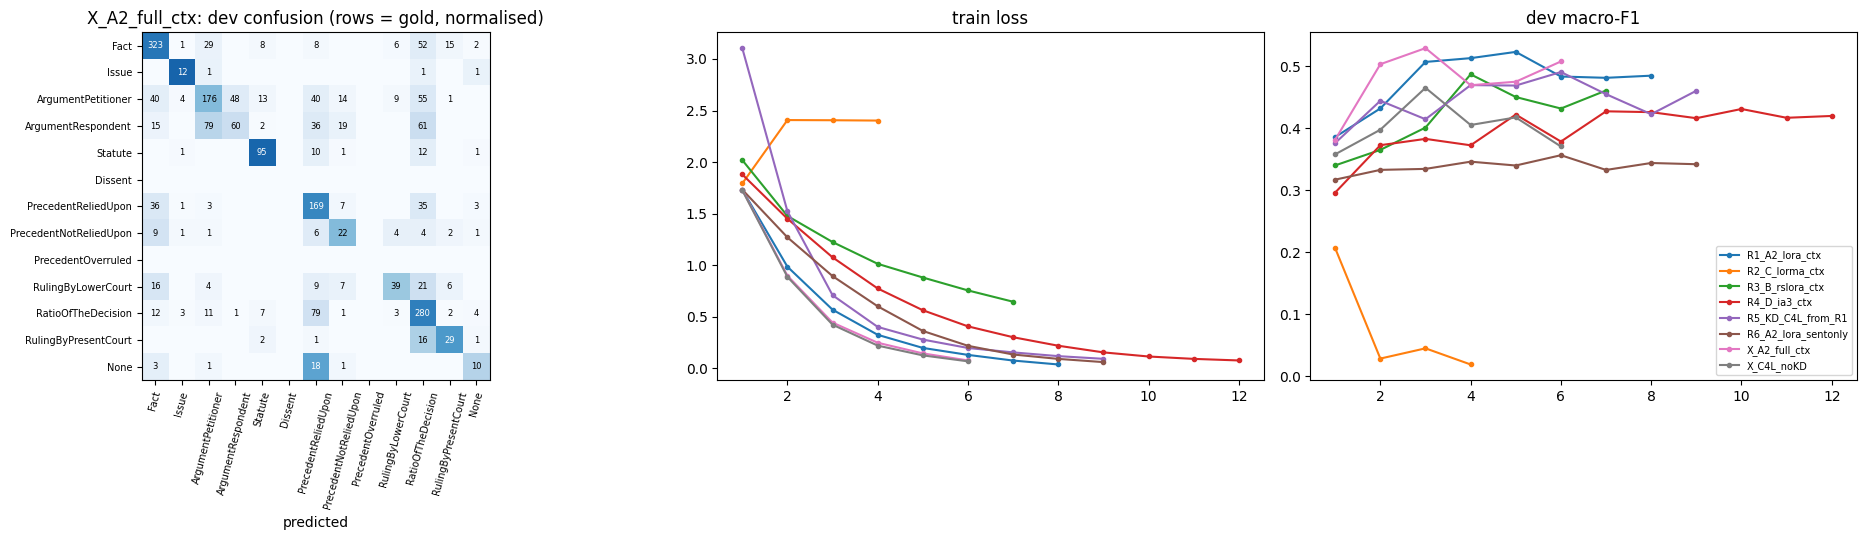

In [27]:
RUN = RES.iloc[0]["run"] if rows else None
if RUN:
    import numpy as np
    import matplotlib.pyplot as plt
    from p3rr.metrics import format_table
    rep = json.load(open(f"{OUT_DIR}/{RUN}/dev_report.json"))
    labels = json.load(open(f"{OUT_DIR}/{RUN}/labels.json"))
    print(RUN); print(format_table(rep["all"]))
    for dom in ("CL", "IT"):
        if dom in rep:
            print(f"\n{dom}: macro-F1 {rep[dom]['macro_f1']:.4f} | macro-P {rep[dom]['macro_p']:.4f} | macro-R {rep[dom]['macro_r']:.4f} | acc {rep[dom]['accuracy']:.4f}")
    print("\nmost frequent confusions (gold -> predicted):"); [print("   ", c) for c in rep["top_confusions"]]
    print(f"\nerrors next to a gold label change: {rep['errors_at_label_change']} | inside a run of the same label: {rep['errors_inside_run']}")
    cm = np.array(rep["confusion"]); cmn = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [1.3, 1, 1]})
    im = ax[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    ax[0].set_xticks(range(len(labels))); ax[0].set_xticklabels(labels, rotation=75, fontsize=7)
    ax[0].set_yticks(range(len(labels))); ax[0].set_yticklabels(labels, fontsize=7)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if cm[i, j]:
                ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > 0.5 else "black")
    ax[0].set_title(f"{RUN}: dev confusion (rows = gold, normalised)"); ax[0].set_xlabel("predicted")
    for r in rows:
        h = json.load(open(f"{OUT_DIR}/{r['run']}/history.json"))
        ax[1].plot([x["epoch"] for x in h], [x["train_loss"] for x in h], "o-", label=r["run"], ms=3)
        ax[2].plot([x["epoch"] for x in h if "dev_macro_f1" in x], [x["dev_macro_f1"] for x in h if "dev_macro_f1" in x], "o-", label=r["run"], ms=3)
    ax[1].set_title("train loss"); ax[2].set_title("dev macro-F1"); ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/analysis_{RUN}.png", dpi=120); plt.show()

## Optional: probability-averaging ensemble → one more submission

In [28]:
ENSEMBLE = []
if ENSEMBLE:
    es = ensemble([f"{OUT_DIR}/{r}" for r in ENSEMBLE], f"{OUT_DIR}/ENS_" + "+".join(ENSEMBLE)[:80], str(DATA_DIR))
    print(es)
    shutil.copy(es["submission"], f"{WORK}/submissions/ENS_{len(ENSEMBLE)}runs{TAG}.zip")
    print(sorted(os.listdir(f"{WORK}/submissions")))

## Download / submit